<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/lab-015-trajectories.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Physical parameters from trajectories

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

A mass on a spring that moves in a fluid is summarised by a physicist with a few numbers. They are the frequency of the oscillation, the rate at which it dies out and the initial position and velocity. We give a neural network only the recorded positions of many such oscillators, each with its own spring, its own friction and its own initial condition, and all of them shaken by a weak random force. One sample $\mathbf x_i$ is the trajectory of one oscillator, its positions at 100 equally spaced times. The network is the β-variational autoencoder (β-VAE) of Lecture 6. It compresses each trajectory into a few latent coordinates, and the weight $\beta$ pushes it to use these coordinates sparingly and independently. Because we simulate the trajectories, we know the true physical parameters of every one of them, and we can check which of these parameters the latent coordinates have learned. The same question was asked by [Iten et al., Phys. Rev. Lett. 124, 010508 (2020)](https://doi.org/10.1103/PhysRevLett.124.010508) for the spring constant and the damping of a pendulum.

We start with the physics of the damped oscillator driven by Gaussian white noise and with its numerical integration, which we test against exact results. We then introduce the data set, train the β-VAE for several values of $\beta$ and several random seeds, and read its latent coordinates with the tools of Lecture 6. These are the active coordinates, correlations, the mutual information gap and latent traversals. An analysis of how sensitive a trajectory is to each parameter explains what the network finds. We then reimplement the question-and-answer network of Iten et al. and compare it with the β-VAE on their pendulum data. In the last part we repeat the experiment for two coupled masses, whose motion depends on the springs only through two normal-mode frequencies. All networks are small and train on a CPU, and their trained weights are saved and loaded on later runs.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""                          # CPU only
import json, time, subprocess, sys
from functools import partial
import numpy as np
import sympy as sp
import scipy.linalg
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize, LogNorm
import torch, torch.nn as nn
from torch.func import jacfwd, vmap
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LinearRegression
try:
    from torchinfo import summary
except ImportError:                                              # e.g. in Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo"], check=True)
    from torchinfo import summary
torch.set_num_threads(8)

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
                     "legend.fontsize": 13, "figure.titlesize": 17})
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "lines.linewidth": 2.0})
blue, orange, navy, gray, sky, light = "#005CA7", "#EB6709", "#0A2F5C", "#5A6270", "#3E8FD0", "#DCE8F5"

OUT = "figures"; os.makedirs(OUT, exist_ok=True)      # figures used on the slides
RES = "results"; os.makedirs(RES, exist_ok=True)                 # trained weights and numbers
TRAIN = False      # True: train every network again; False: load the saved weights from results/ when they exist
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=200, bbox_inches="tight")
nums = {}                                                        # numbers quoted on the slides
t_start = time.time()
print("PyTorch", torch.__version__, "| threads", torch.get_num_threads())

PyTorch 2.9.0+cpu | threads 8


## The noisy damped oscillator

### Langevin equation

A particle of mass $m$ is attached to a spring of spring constant $k$ and moves in a viscous fluid. The spring pulls it back with a force proportional to the displacement, the fluid slows it down with a friction force proportional to the velocity, and the molecules of the fluid hit it at random. Dividing Newton's equation by $m$ we obtain the Langevin equation of the damped oscillator,
$$
\ddot x=-\omega^2x-\gamma\dot x+\sqrt{2D}\,\xi(t), \tag{1}
$$
with the angular frequency of the oscillator without friction
$$
\omega=\sqrt{k/m}. \tag{2}
$$
Equation (1) is a stochastic differential equation (SDE), a differential equation with a random term. Its solution is a random function of time, and every realisation of the random force gives a different trajectory. The friction rate $\gamma$ is the inverse of the time in which friction alone would stop a free particle. The random force $\xi(t)$ is Gaussian white noise, a Gaussian random function with
$$
\langle\xi(t)\rangle=0,\qquad\langle\xi(t)\,\xi(t')\rangle=\delta(t-t'), \tag{3}
$$
so its values at different times are independent, however close the times are. The brackets $\langle\cdot\rangle$ denote the average over many realisations of the noise. The constant $D$ is the noise strength and sets the size of the random force. Since $\xi$ has the unit $\mathrm{s}^{-1/2}$, the noise strength has the unit $\mathrm{m}^2/\mathrm{s}^3$. Equation (19) will show that in the stationary state the mean squared velocity is the ratio of $D$ and $\gamma$. If the random force comes from a fluid at temperature $T$, equipartition fixes the mean squared velocity at $k_BT/m$, with the Boltzmann constant $k_B$, and therefore
$$
D=\frac{\gamma\,k_BT}{m}. \tag{4}
$$
Friction and noise thus have the same molecular origin and are tied together by this Einstein relation. All quantities in the notebook are dimensionless, in units in which the mass equals one.

Without noise the equation is linear. The exponential ansatz $e^{\lambda t}$ for $x(t)$ gives the characteristic equation
$$
\lambda^2+\gamma\lambda+\omega^2=0 \tag{5}
$$
with the roots
$$
\lambda_\pm=-\frac\gamma2\pm\sqrt{\frac{\gamma^2}{4}-\omega^2}. \tag{6}
$$
Two regimes follow from the sign of the expression under the root. In the underdamped regime,
$$
\gamma<2\omega, \tag{7}
$$
the roots are complex, and the particle oscillates at the damped frequency
$$
\omega_d=\sqrt{\omega^2-\gamma^2/4} \tag{8}
$$
inside an exponentially decaying envelope,
$$
x(t)=e^{-\gamma t/2}\Big[x_0\cos\omega_dt+\frac{v_0+\gamma x_0/2}{\omega_d}\sin\omega_dt\Big], \tag{9}
$$
where $x_0$ and $v_0$ are the initial position and velocity. The frequency $\omega$ sets how often the particle crosses zero, and the friction rate $\gamma$ sets how fast the oscillation dies out. In the overdamped regime, when $\gamma$ exceeds $2\omega$, both roots are real and negative. The particle then creeps back to the origin without oscillating, and the slower of the two rates dominates at long times. At the boundary between the two regimes, called critical damping, the return to the origin is fastest. We check the roots and the underdamped solution (9) with SymPy and expand the slow rate for strong friction.

In [2]:
t, w, g = sp.symbols("t omega gamma", positive=True)
lam, x0s, v0s = sp.symbols("lambda x_0 v_0")

# characteristic equation of  x'' + gamma x' + omega^2 x = 0  for x = exp(lambda t)
roots = sp.solve(sp.Eq(lam**2 + g * lam + w**2, 0), lam)
print("lambda =", roots)

# underdamped solution with x(0) = x0, x'(0) = v0
wd = sp.sqrt(w**2 - g**2 / 4)
x_under = sp.exp(-g * t / 2) * (x0s * sp.cos(wd * t) + (v0s + g * x0s / 2) / wd * sp.sin(wd * t))
print("residual of the equation of motion:", sp.simplify(sp.diff(x_under, t, 2) + g * sp.diff(x_under, t) + w**2 * x_under))
print("x(0) =", x_under.subs(t, 0), "   x'(0) =", sp.simplify(sp.diff(x_under, t).subs(t, 0)))

# overdamped: the slower of the two decay rates, expanded for omega << gamma
rate_slow = g / 2 - sp.sqrt(g**2 / 4 - w**2)
print("slow decay rate for omega << gamma:", sp.series(rate_slow, w, 0, 5).removeO())

lambda = [-gamma/2 - sqrt(gamma**2 - 4*omega**2)/2, -gamma/2 + sqrt(gamma**2 - 4*omega**2)/2]


residual of the equation of motion: 0
x(0) = x_0    x'(0) = v_0
slow decay rate for omega << gamma: omega**2/gamma + omega**4/gamma**3


The residual vanishes and the initial conditions are reproduced. For strong friction the slow rate is
$$
|\lambda_+|\approx\frac{\omega^2}{\gamma}+\frac{\omega^4}{\gamma^3}. \tag{10}
$$
Deep in the overdamped regime a trajectory therefore depends on $\omega$ and $\gamma$ essentially only through the combination $\omega^2/\gamma$, and we will test the latent coordinates against this prediction.

For any regime we can write the noise-free motion compactly with the state vector $\mathbf s$, which collects the position and the velocity,
$$
\dot{\mathbf s}=A\mathbf s,\qquad A=\begin{pmatrix}0&1\\-\omega^2&-\gamma\end{pmatrix},\qquad\mathbf s(t)=e^{At}\,\mathbf s(0), \tag{11}
$$
where $A$ is the drift matrix. The function `mean_trajectory` evaluates the matrix exponential with `torch.linalg.matrix_exp`. In the section on the exact mean we show that the same function gives the mean of the noisy trajectories, so it serves as the exact reference throughout. Since it is differentiable, it also provides the derivatives of a trajectory with respect to the parameters, which we need for the sensitivity analysis.

In [3]:
def mean_trajectory(p, t):
    """Noise-free trajectory: first component of expm(A t) (x0, v0); p = (omega, gamma, x0, v0) and t (T,), float64 tensors."""
    omega, gamma, x0, v0 = p
    zero, one = torch.zeros_like(omega), torch.ones_like(omega)
    A = torch.stack([torch.stack([zero, one]), torch.stack([-omega**2, -gamma])])        # drift matrix
    return (torch.linalg.matrix_exp(A * t[:, None, None]) @ torch.stack([x0, v0]))[:, 0]

def mean_trajectories(F, t):
    """Many trajectories at once: F (N, 4) = (omega, gamma, x0, v0), times t (T,) -> numpy array (N, T)."""
    return vmap(mean_trajectory, in_dims=(0, None))(torch.as_tensor(np.asarray(F, float), dtype=torch.float64),
                                                    torch.as_tensor(np.asarray(t, float), dtype=torch.float64)).numpy()

# the matrix exponential agrees with the analytic underdamped solution of SymPy
f_under = sp.lambdify((t, w, g, x0s, v0s), x_under, "numpy")
tt = np.linspace(0, 6, 7)
print("max |expm - analytic underdamped solution| =",
      np.abs(mean_trajectories([[1.5, 0.4, 1.0, 0.3]], tt)[0] - f_under(tt, 1.5, 0.4, 1.0, 0.3)).max())

max |expm - analytic underdamped solution| = 1.4432899320127035e-15


The figure shows the system and the effect of the two parameters. In the middle panel only $\omega$ changes. The zero crossings move closer together as $\omega$ grows, while the envelope stays the same. In the right panel only $\gamma$ changes, and the motion goes from a slowly decaying oscillation ($\gamma=0.2$) through a strongly damped one ($\gamma=1$) to an overdamped creep without any oscillation ($\gamma=5$, larger than $2\omega=3$).

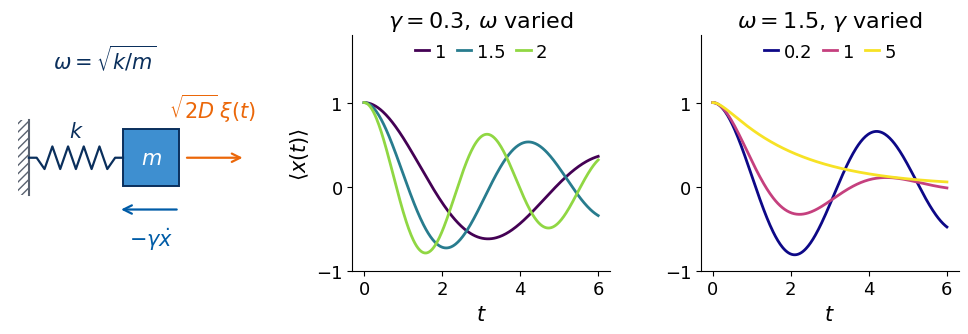

In [4]:
def draw_spring(ax, x_start, x_end, y, n_coils=6, height=0.12):
    """Zig-zag spring between (x_start, y) and (x_end, y)."""
    xs = np.linspace(x_start, x_end, 2 * n_coils + 3)
    ys = np.full_like(xs, y)
    ys[1:-1:2] += height; ys[2:-1:2] -= height
    ys[1], ys[-2] = y, y                                           # straight ends
    ax.plot(xs, ys, color=navy, lw=1.6)

def draw_wall(ax, x, y0, y1, side="left"):
    """Hatched wall at x between heights y0 and y1."""
    w_ = -0.12 if side == "left" else 0.12
    ax.add_patch(Rectangle((x, y0), w_, y1 - y0, facecolor="none", edgecolor=gray, hatch="////", lw=0))
    ax.plot([x, x], [y0, y1], color=gray, lw=1.5)

def draw_oscillator_sketch(ax):
    """Mass on a spring with friction and a random force."""
    draw_wall(ax, 0.0, -0.4, 0.4)
    draw_spring(ax, 0.0, 1.0, 0.0, n_coils=5)
    ax.add_patch(Rectangle((1.0, -0.3), 0.6, 0.6, facecolor=sky, edgecolor=navy, lw=1.4))
    ax.text(1.3, 0.0, "$m$", ha="center", va="center", fontsize=15, color="white")
    ax.text(0.5, 0.22, "$k$", ha="center", fontsize=15, color=navy)
    ax.annotate("", xy=(2.3, 0.0), xytext=(1.65, 0.0), arrowprops=dict(arrowstyle="->", color=orange, lw=1.6))
    ax.text(1.95, 0.42, r"$\sqrt{2D}\,\xi(t)$", ha="center", fontsize=15, color=orange)
    ax.annotate("", xy=(0.95, -0.55), xytext=(1.6, -0.55), arrowprops=dict(arrowstyle="->", color=blue, lw=1.6))
    ax.text(1.3, -0.72, r"$-\gamma\dot x$", ha="center", va="top", fontsize=15, color=blue)
    ax.text(0.8, 0.95, r"$\omega=\sqrt{k/m}$", ha="center", fontsize=15, color=navy)
    ax.set_xlim(-0.2, 2.4); ax.set_ylim(-1.2, 1.3); ax.set_aspect("equal"); ax.axis("off")

t_demo = np.linspace(0, 6, 300)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.0, 1, 1]))
draw_oscillator_sketch(axs[0])
for om in [1.0, 1.5, 2.0]:
    axs[1].plot(t_demo, mean_trajectories([[om, 0.3, 1.0, 0.0]], t_demo)[0], color=plt.cm.viridis((om - 1) / 1.2), label=f"{om:g}")
for ga in [0.2, 1.0, 5.0]:
    axs[2].plot(t_demo, mean_trajectories([[1.5, ga, 1.0, 0.0]], t_demo)[0], color=plt.cm.plasma(np.log(ga / 0.2) / np.log(30)),
                label=f"{ga:g}")
axs[1].set_title(r"$\gamma=0.3$, $\omega$ varied"); axs[2].set_title(r"$\omega=1.5$, $\gamma$ varied")
for a in axs[1:]:
    a.legend(loc="upper center", ncol=3, handlelength=0.8, columnspacing=0.6, handletextpad=0.3, borderaxespad=0.0)
    a.set_xlabel("$t$"); a.set_ylim(-1.0, 1.8); a.set_yticks([-1, 0, 1])
axs[1].set_ylabel(r"$\langle x(t)\rangle$")
plt.tight_layout(); save_fig(fig, "traj_oscillator.png"); plt.show()

### Euler–Maruyama integration

To simulate equation (1) we write it as two first-order equations, for $x$ and for the velocity $v$, and integrate them over one small time step $\Delta t$. The integral of $\xi$ over one step is the increment $\Delta W$ of the Wiener process, the mathematical model of Brownian motion. It is Gaussian with mean zero, and by equation (3) its variance equals the step,
$$
\Delta W=\int_t^{t+\Delta t}\xi(s)\,ds,\qquad\langle\Delta W^2\rangle=\int_t^{t+\Delta t}\!\!\int_t^{t+\Delta t}\langle\xi(s)\xi(s')\rangle\,ds\,ds'=\Delta t. \tag{12}
$$
We can therefore write it as
$$
\Delta W=\sqrt{\Delta t}\,\eta,\qquad\eta\sim\mathcal N(0,1), \tag{13}
$$
and increments over different steps are independent. Approximating the smooth terms by their values at the beginning of the step we obtain the update
$$
\begin{aligned}
x_{n+1}&=x_n+v_n\,\Delta t,\\
v_{n+1}&=v_n+\big(-\omega^2x_n-\gamma v_n\big)\Delta t+\sqrt{2D\,\Delta t}\;\eta_n,
\end{aligned} \tag{14}
$$
with independent standard Gaussian numbers $\eta_n$. This is the Euler–Maruyama scheme [Kloeden and Platen 1992, Higham 2001], the stochastic counterpart of the Euler method for ordinary differential equations. It differs from the ordinary Euler method by the factor $\sqrt{\Delta t}$ in the noise term. The random kicks of many steps add up like a random walk, so their typical size grows as the square root of the elapsed time (Exercise 1). Averages computed with the scheme converge to the exact ones with an error proportional to $\Delta t$, which is called weak order one. We use $\Delta t=0.01$, small compared with the shortest time scales of the data, the inverse frequency (at least 0.5) and the inverse friction rate (at least 1/6).

The function `simulate` integrates many oscillators at once, vectorised over the trajectories with NumPy, and records every `n_sub`-th step.

In [5]:
DT = 0.01            # Euler-Maruyama time step
D_NOISE = 0.002      # noise strength D of all data sets

def simulate(omega, gamma, x0, v0, rng, D=D_NOISE, dt=DT, n_sub=6, n_rec=100, drive=None):
    """Euler-Maruyama for N independent oscillators; omega, gamma, x0, v0 are arrays of shape (N,).
    drive: optional function of the time returning an additional force (N,).
    Returns positions and velocities (N, n_rec) at the times 0, n_sub*dt, 2*n_sub*dt, ..."""
    x, v = np.array(x0, float), np.array(v0, float)
    X, V = np.empty((len(x), n_rec)), np.empty((len(x), n_rec))
    X[:, 0], V[:, 0] = x, v
    kick = np.sqrt(2 * D * dt)                                     # the noise term scales as sqrt(dt)
    n = 0
    for i in range(1, n_rec):
        for _ in range(n_sub):                                     # n_sub steps between two recorded points
            a = -omega**2 * x - gamma * v + (drive(n * dt) if drive is not None else 0.0)
            x, v = x + v * dt, v + a * dt + kick * rng.standard_normal(len(x))
            n += 1
        X[:, i], V[:, i] = x, v
    return X, V

### Exact mean and stationary variance

Averaging the update (14) over the noise removes the term with $\eta_n$, because its mean vanishes and the update is linear. The averages of $x_n$ and $v_n$ therefore obey the noise-free recursion, and for vanishing $\Delta t$ the mean trajectory is the noise-free solution (11).

For the fluctuations we write the update as
$$
\mathbf s_{n+1}=M\mathbf s_n+\mathbf b\,\eta_n,\qquad M=I+A\,\Delta t,\qquad\mathbf b=\begin{pmatrix}0\\\sqrt{2D\,\Delta t}\end{pmatrix}. \tag{15}
$$
Since $\eta_n$ is independent of $\mathbf s_n$, the covariance matrix
$$
\Sigma=\langle\mathbf s\mathbf s^{\mathsf T}\rangle-\langle\mathbf s\rangle\langle\mathbf s\rangle^{\mathsf T} \tag{16}
$$
obeys
$$
\Sigma_{n+1}=M\Sigma_nM^{\mathsf T}+\mathbf b\mathbf b^{\mathsf T},\qquad
\frac{\Sigma_{n+1}-\Sigma_n}{\Delta t}=A\Sigma_n+\Sigma_nA^{\mathsf T}+Q+O(\Delta t),\qquad Q=\begin{pmatrix}0&0\\0&2D\end{pmatrix}. \tag{17}
$$
In the stationary state the left-hand side of the second relation vanishes, and the covariance solves the Lyapunov equation
$$
A\Sigma+\Sigma A^{\mathsf T}+Q=0. \tag{18}
$$
These are three linear equations for the second moments of position and velocity, which we solve with SymPy.

In [6]:
Sxx, Sxv, Svv, D_s = sp.symbols("S_xx S_xv S_vv D", real=True)
A_s = sp.Matrix([[0, 1], [-w**2, -g]])
Sig = sp.Matrix([[Sxx, Sxv], [Sxv, Svv]])
Q_s = sp.diag(0, 2 * D_s)
sol = sp.solve(list(A_s * Sig + Sig * A_s.T + Q_s), [Sxx, Sxv, Svv], dict=True)[0]
print("stationary <x^2> =", sol[Sxx], "   <x v> =", sol[Sxv], "   <v^2> =", sol[Svv])

stationary <x^2> = D/(gamma*omega**2)    <x v> = 0    <v^2> = D/gamma


The stationary second moments are
$$
\langle x^2\rangle=\frac{D}{\gamma\omega^2},\qquad\langle xv\rangle=0,\qquad\langle v^2\rangle=\frac D\gamma, \tag{19}
$$
and the velocity variance is the one used for the Einstein relation (4). In the overdamped limit the inertia can be neglected, and the particle obeys
$$
\gamma\dot x=-\omega^2x+\sqrt{2D}\,\xi(t). \tag{20}
$$
This is the Ornstein–Uhlenbeck process [Uhlenbeck and Ornstein 1930], a Gaussian process with a drift back to the origin whose correlations decay exponentially in time. Its stationary position variance is the same as in equation (19) (Exercise 2). For a particle that starts at a fixed point the covariance at time $t$ is
$$
\Sigma(t)=\Sigma_\infty-e^{At}\,\Sigma_\infty\,e^{A^{\mathsf T}t}, \tag{21}
$$
where $\Sigma_\infty$ is the stationary solution of equation (18). This expression solves the continuum form of equation (17) and vanishes at the start.

We test the integrator against these results with 20 000 realisations at $\omega=1.5$, $\gamma=0.5$, $x_0=1$ and $v_0=0$ up to time 40. We compare the ensemble mean with equation (11) and the ensemble variance with equation (21). The Euler–Maruyama recursion itself has a stationary covariance, the solution of the first relation in equation (17) with equal $\Sigma_{n+1}$ and $\Sigma_n$. This discrete Lyapunov equation is solved by `scipy.linalg.solve_discrete_lyapunov`, and comparing its solution with equation (19) shows how large the error of order $\Delta t$ is.

max |ensemble mean - noise-free Euler recursion| = 0.0005   (standard error of the mean ~ 0.0003)
max |noise-free Euler recursion - exact mean|  = 0.0172   (time-discretisation error)
<x^2>: exact D/(gamma omega^2) = 0.001778, Euler-Maruyama recursion = 0.001862, ensemble (t in [30, 40]) = 0.001864
<v^2>: exact D/gamma           = 0.004000, Euler-Maruyama recursion = 0.004199, ensemble (t in [30, 40]) = 0.004207
relative statistical error of one variance estimate ~ sqrt(2/N) = 0.010


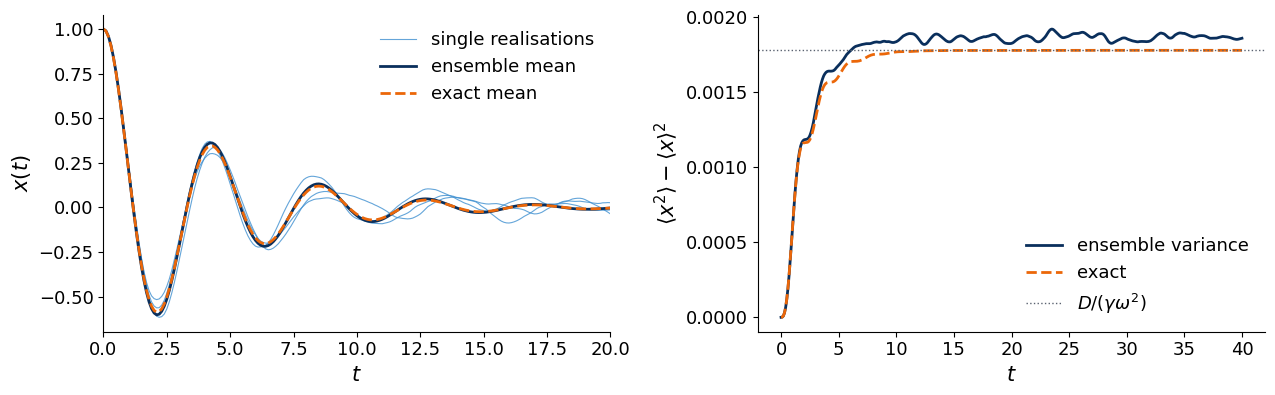

In [7]:
# one parameter point, 20 000 independent realisations up to t = 40
om_c, ga_c, n_ens = 1.5, 0.5, 20_000
ones = np.ones(n_ens)
X_ens, V_ens = simulate(om_c * ones, ga_c * ones, ones, 0 * ones, np.random.default_rng(0), n_sub=10, n_rec=401)
t_ens = 10 * DT * np.arange(401)

# exact mean and exact variance of x(t) for the deterministic start (1, 0)
A_c = np.array([[0.0, 1.0], [-om_c**2, -ga_c]])
Sig_inf = np.diag([D_NOISE / (ga_c * om_c**2), D_NOISE / ga_c])
var_exact = np.array([(Sig_inf - scipy.linalg.expm(A_c * s) @ Sig_inf @ scipy.linalg.expm(A_c * s).T)[0, 0] for s in t_ens])
mean_exact = mean_trajectories([[om_c, ga_c, 1.0, 0.0]], t_ens)[0]
X_det = simulate(np.array([om_c]), np.array([ga_c]), np.ones(1), np.zeros(1), np.random.default_rng(1), D=0.0,
                 n_sub=10, n_rec=401)[0][0]

# stationary covariance of the Euler-Maruyama recursion itself (discrete Lyapunov equation)
M_c = np.eye(2) + A_c * DT
Sig_em = scipy.linalg.solve_discrete_lyapunov(M_c, np.diag([0, 2 * D_NOISE * DT]))

late = t_ens >= 30
var_x_meas, var_v_meas = X_ens[:, late].var(0).mean(), V_ens[:, late].var(0).mean()
print(f"max |ensemble mean - noise-free Euler recursion| = {np.abs(X_ens.mean(0) - X_det).max():.4f}"
      f"   (standard error of the mean ~ {np.sqrt(var_exact.max() / n_ens):.4f})")
print(f"max |noise-free Euler recursion - exact mean|  = {np.abs(X_det - mean_exact).max():.4f}   (time-discretisation error)")
print(f"<x^2>: exact D/(gamma omega^2) = {Sig_inf[0, 0]:.6f}, Euler-Maruyama recursion = {Sig_em[0, 0]:.6f}, "
      f"ensemble (t in [30, 40]) = {var_x_meas:.6f}")
print(f"<v^2>: exact D/gamma           = {Sig_inf[1, 1]:.6f}, Euler-Maruyama recursion = {Sig_em[1, 1]:.6f}, "
      f"ensemble (t in [30, 40]) = {var_v_meas:.6f}")
print(f"relative statistical error of one variance estimate ~ sqrt(2/N) = {np.sqrt(2 / n_ens):.3f}")
nums["em_var_x"] = {"exact": float(Sig_inf[0, 0]), "em_recursion": float(Sig_em[0, 0]), "ensemble": float(var_x_meas)}
nums["em_var_v"] = {"exact": float(Sig_inf[1, 1]), "em_recursion": float(Sig_em[1, 1]), "ensemble": float(var_v_meas)}

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for i in range(3):
    axs[0].plot(t_ens, X_ens[i], color=sky, lw=0.8, alpha=0.8, label="single realisations" if i == 0 else None)
axs[0].plot(t_ens, X_ens.mean(0), color=navy, label="ensemble mean")
axs[0].plot(t_ens, mean_exact, "--", color=orange, label="exact mean")
axs[0].set_xlim(0, 20); axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$x(t)$"); axs[0].legend()
axs[1].plot(t_ens, X_ens.var(0), color=navy, label="ensemble variance")
axs[1].plot(t_ens, var_exact, "--", color=orange, label="exact")
axs[1].axhline(Sig_inf[0, 0], color=gray, lw=1, ls=":", label=r"$D/(\gamma\omega^2)$")
axs[1].set_xlabel("$t$"); axs[1].set_ylabel(r"$\langle x^2\rangle-\langle x\rangle^2$"); axs[1].legend()
plt.tight_layout(); plt.show()

The ensemble mean agrees with the noise-free Euler recursion to 0.0005, which is below two standard errors of the mean (0.0003) for the largest of 401 deviations. The recursion itself differs from the exact mean by up to 0.0172. This is the time-discretisation error of the Euler method, accumulated over 40 time units. The variances show the same picture. The ensemble gives a position variance of 0.001864 and a velocity variance of 0.004207, and the stationary covariance of the Euler–Maruyama recursion predicts 0.001862 and 0.004199, within the statistical error of about 1%. Both lie about 5% above the exact values 0.001778 and 0.004000 of equation (19). This difference is an error of order $\Delta t$ of the scheme and does not come from the sampling. In the right panel the variance grows from zero, as equation (21) predicts, and then fluctuates around the stationary value of the recursion. For the weak noise of our data this accuracy is sufficient.

## Trajectory data

We simulate the data with equation (1), so nothing is downloaded. One sample of the data set is the trajectory of one oscillator,
$$
\mathbf x_i=\big(x_i(t_0),x_i(t_1),\dots,x_i(t_{99})\big)\in\mathbb R^{100},\qquad t_j=0.06\,j, \tag{22}
$$
the position of the mass at 100 equally spaced times that cover the window from 0 to 5.94. All quantities are dimensionless. The mass is one, times are measured in a unit in which the frequencies are of order one, and positions in the unit of a typical initial displacement. Every trajectory has its own physical parameters and its own initial condition, drawn independently from
$$
\omega\sim\mathcal U[1,2],\qquad\ln\gamma\sim\mathcal U[\ln0.2,\ln6],\qquad x_0\sim\mathcal U[0.5,1.5],\qquad v_0\sim\mathcal U[-0.5,0.5], \tag{23}
$$
where $\mathcal U[a,b]$ denotes the uniform distribution on the interval from $a$ to $b$. The friction rate is log-uniform, so every factor of $e$ in the friction is equally represented over its range from 0.2 to 6. The noise strength $D=0.002$ is the same for all trajectories. We integrate each trajectory with the update (14) at $\Delta t=0.01$ and record every sixth step. The training set has 20 000 trajectories and the test set 5000, simulated with different random seeds. Both regimes of equation (7) are present.

We call the four numbers $(\omega,\gamma,x_0,v_0)$ the factors of a trajectory. Only $\omega$ and $\gamma$ are properties of the oscillator. The initial position and velocity are nuisance factors, which change the trajectory without describing the system. The factors serve as labels for the evaluation only, and the networks never see them.

The ranges are a deliberate choice. Over the window the oscillation completes about one to two periods, and the initial position is always positive, so a trajectory cannot be turned into another one by flipping its sign. Wider ranges, with many periods in the window or with initial positions of both signs, make the task much harder for the network, and the sensitivity analysis explains why.

In [8]:
OMEGA_RANGE = (1.0, 2.0)       # uniform
GAMMA_RANGE = (0.2, 6.0)       # log-uniform
X0_RANGE = (0.5, 1.5)          # uniform
V0_MAX = 0.5                   # v0 uniform in [-V0_MAX, V0_MAX]
N_SUB, T_POINTS = 6, 100       # record every 6th Euler-Maruyama step: 100 points, spacing 0.06
t_grid = N_SUB * DT * np.arange(T_POINTS)
FACTOR_NAMES = [r"$\omega$", r"$\ln\gamma$", r"$x_0$", r"$v_0$"]

def make_oscillator_data(n, seed, D=D_NOISE):
    """n noisy trajectories (n, 100) and their factors (n, 4) = (omega, gamma, x0, v0)."""
    rng = np.random.default_rng(seed)
    om = rng.uniform(*OMEGA_RANGE, n)
    ga = np.exp(rng.uniform(np.log(GAMMA_RANGE[0]), np.log(GAMMA_RANGE[1]), n))
    x0 = rng.uniform(*X0_RANGE, n)
    v0 = rng.uniform(-V0_MAX, V0_MAX, n)
    X, _ = simulate(om, ga, x0, v0, rng, D=D, n_sub=N_SUB, n_rec=T_POINTS)
    return X.astype(np.float32), np.stack([om, ga, x0, v0], 1)

Xtr, Ftr = make_oscillator_data(20_000, seed=1)
Xte, Fte = make_oscillator_data(5_000, seed=2)
probe_factors = lambda F: np.stack([F[:, 0], np.log(F[:, 1]), F[:, 2], F[:, 3]], 1)   # omega, ln gamma, x0, v0
Pte = probe_factors(Fte)
over_te = Fte[:, 1] > 2 * Fte[:, 0]

# the noise: deviation of every test trajectory from its exact mean
Mte = mean_trajectories(Fte, t_grid)
dev = Xte - Mte
print(f"training / test trajectories: {Xtr.shape} / {Xte.shape};  times t_j = {t_grid[1]:.2f} j, window [0, {t_grid[-1]:.2f}]")
for name, col in zip(["omega", "gamma", "x0", "v0"], Ftr.T):
    print(f"  {name:6s} in the training set: min {col.min():.3f}, max {col.max():.3f}")
print(f"overdamped (gamma > 2 omega): {100 * (Ftr[:, 1] > 2 * Ftr[:, 0]).mean():.1f}% of the training set")
print(f"standard deviation of all positions: {Xtr.std():.3f};  rms deviation from the mean trajectory: {np.sqrt((dev**2).mean()):.4f}")
print("\nthree training samples: factors (omega, gamma, x0, v0) and the first five positions x_i(t_0), ..., x_i(t_4)")
for i in range(3):
    print(f"  x_{i}: factors {np.round(Ftr[i], 3)},  positions {np.round(Xtr[i, :5], 3)}")
nums["data"] = {"n_train": int(Xtr.shape[0]), "n_test": int(Xte.shape[0]), "overdamped_frac": float((Ftr[:, 1] > 2 * Ftr[:, 0]).mean()),
                "x_std": float(Xtr.std()), "noise_rms": float(np.sqrt((dev**2).mean()))}

training / test trajectories: (20000, 100) / (5000, 100);  times t_j = 0.06 j, window [0, 5.94]
  omega  in the training set: min 1.000, max 2.000
  gamma  in the training set: min 0.200, max 5.999
  x0     in the training set: min 0.500, max 1.500
  v0     in the training set: min -0.500, max 0.500
overdamped (gamma > 2 omega): 20.9% of the training set
standard deviation of all positions: 0.430;  rms deviation from the mean trajectory: 0.0315

three training samples: factors (omega, gamma, x0, v0) and the first five positions x_i(t_0), ..., x_i(t_4)
  x_0: factors [1.512 0.681 0.645 0.393],  positions [0.645 0.667 0.682 0.692 0.696]
  x_1: factors [ 1.95   0.979  0.775 -0.324],  positions [0.775 0.751 0.718 0.678 0.631]
  x_2: factors [ 1.144  0.904  0.623 -0.283],  positions [0.623 0.606 0.587 0.565 0.542]


The sampled factors fill the ranges of equation (23), and 20.9% of the training trajectories are overdamped. The positions have a standard deviation of 0.430 over the data set, while the random force moves a trajectory away from its mean by 0.0315 (root mean square over all times and test trajectories). The noise is thus a small but visible perturbation of about 7% of the signal. The printed rows show what the network receives, a list of 100 positions per trajectory that starts at $x_0$ and changes smoothly in time, while the factors next to them stay hidden from it.

The figure shows test trajectories selected so that mainly one parameter varies. On the left the friction rate lies between 0.30 and 0.37, the initial position near 1 and the initial velocity near 0, and the frequency goes from 1.01 to 2.00. On the right the frequency lies between 1.45 and 1.56 and the friction rate goes from 0.25 to 5.88. The small wiggles are the random force.

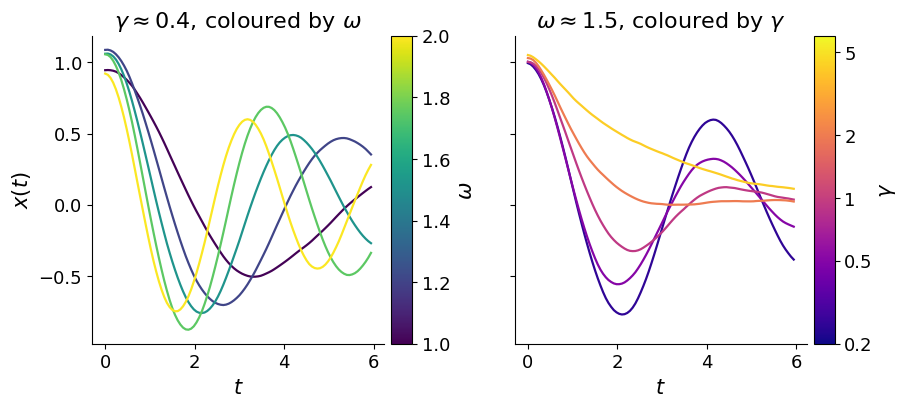

left:  (omega, gamma) = [(np.float64(1.01), np.float64(0.37)), (np.float64(1.2), np.float64(0.35)), (np.float64(1.52), np.float64(0.36)), (np.float64(1.75), np.float64(0.3)), (np.float64(2.0), np.float64(0.35))]
right: (omega, gamma) = [(np.float64(1.5), np.float64(0.25)), (np.float64(1.53), np.float64(0.56)), (np.float64(1.47), np.float64(1.1)), (np.float64(1.56), np.float64(2.56)), (np.float64(1.45), np.float64(5.88))]


In [9]:
def pick(mask, key, targets):
    """Indices of the test trajectories inside mask whose factor `key` is closest to each target value."""
    idx = np.flatnonzero(mask)
    return [idx[np.argmin(np.abs(Fte[idx, key] - tv))] for tv in targets]

near = lambda k, lo, hi: (Fte[:, k] >= lo) & (Fte[:, k] <= hi)
sel_w = pick(near(1, 0.3, 0.45) & near(2, 0.9, 1.1) & near(3, -0.1, 0.1), 0, np.linspace(1.0, 2.0, 5))
sel_g = pick(near(0, 1.4, 1.6) & near(2, 0.9, 1.1) & near(3, -0.1, 0.1), 1, np.exp(np.linspace(np.log(0.25), np.log(5.5), 5)))
norm_w, norm_g = Normalize(*OMEGA_RANGE), LogNorm(*GAMMA_RANGE)

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for i in sel_w:
    axs[0].plot(t_grid, Xte[i], color=plt.cm.viridis(norm_w(Fte[i, 0])), lw=1.6)
for i in sel_g:
    axs[1].plot(t_grid, Xte[i], color=plt.cm.plasma(norm_g(Fte[i, 1]) * 0.9), lw=1.6)
cb = fig.colorbar(plt.cm.ScalarMappable(norm_w, "viridis"), ax=axs[0], pad=0.02, aspect=15); cb.set_label(r"$\omega$")
cb = fig.colorbar(plt.cm.ScalarMappable(norm_g, "plasma"), ax=axs[1], pad=0.02, aspect=15); cb.set_label(r"$\gamma$")
cb.set_ticks([0.2, 0.5, 1, 2, 5]); cb.set_ticklabels(["0.2", "0.5", "1", "2", "5"]); cb.minorticks_off()
axs[0].set_title(r"$\gamma\approx0.4$, coloured by $\omega$"); axs[1].set_title(r"$\omega\approx1.5$, coloured by $\gamma$")
for a in axs: a.set_xlabel("$t$")
axs[0].set_ylabel("$x(t)$")
save_fig(fig, "traj_examples.png"); plt.show()
print("left:  (omega, gamma) =", [tuple(np.round(Fte[i, :2], 2)) for i in sel_w])
print("right: (omega, gamma) =", [tuple(np.round(Fte[i, :2], 2)) for i in sel_g])

Faster oscillators cross zero earlier and more often within the window. Stronger friction removes the oscillation, and the largest friction rates give a slow monotonic decay.

## β-VAE for trajectories

### Gaussian likelihood and the β-VAE loss

We use the notation of Lecture 6. A trajectory $\mathbf x\in\mathbb R^T$, with $T=100$ positions, is described by a latent vector $\mathbf z\in\mathbb R^d$ with the prior $p(\mathbf z)$ and the encoder distribution $q_\phi(\mathbf z|\mathbf x)$,
$$
p(\mathbf z)=\mathcal N(0,I_d),\qquad q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\mathrm{diag}\,\boldsymbol\sigma^2_\phi(\mathbf x)\big), \tag{24}
$$
and the decoder defines a probability distribution of trajectories $p_\theta(\mathbf x|\mathbf z)$. Positions are real numbers, and the natural choice is a Gaussian likelihood. Given $\mathbf z$, every recorded position is Gaussian around the value of a decoder network $G_\theta(\mathbf z)$, with a fixed standard deviation $\sigma_x$,
$$
p_\theta(\mathbf x|\mathbf z)=\prod_{i=1}^T\frac{1}{\sqrt{2\pi\sigma_x^2}}\exp\Big[-\frac{\big(x_i-G_\theta(\mathbf z)_i\big)^2}{2\sigma_x^2}\Big],\qquad
-\log p_\theta(\mathbf x|\mathbf z)=\frac{1}{2\sigma_x^2}\big\lVert\mathbf x-G_\theta(\mathbf z)\big\rVert^2+\frac T2\log(2\pi\sigma_x^2). \tag{25}
$$
The reconstruction term is therefore proportional to the mean squared error (MSE), the average squared deviation of the reconstruction from the data,
$$
\mathrm{MSE}=\frac1T\sum_{i=1}^T\big(x_i-G_\theta(\mathbf z)_i\big)^2, \tag{26}
$$
multiplied by $T/(2\sigma_x^2)$, plus a constant that does not affect training. The decoder output $G_\theta(\mathbf z)$ is the mean of the trajectory given $\mathbf z$, a smooth curve without the noise. The scale $\sigma_x$ says how large a deviation the model tolerates. We set it to 0.1, about three times the typical deviation of a noisy trajectory from its mean (measured in the data section), so the model gains little by storing the noise.

The β-VAE loss of Lecture 6 is
$$
\mathcal L_\beta(\mathbf x)=\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\Big[\frac{1}{2\sigma_x^2}\big\lVert\mathbf x-G_\theta(\mathbf z)\big\rVert^2\Big]}_{\text{distortion}}+\beta\,\underbrace{\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)}_{\text{rate}}, \tag{27}
$$
with the Kullback–Leibler (KL) divergence of the encoder distribution from the prior,
$$
\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)=\frac12\sum_{k=1}^d\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big). \tag{28}
$$
The KL divergence measures, in nats (units of information with the natural logarithm), how much the encoder distribution of one trajectory differs from the prior. It vanishes only when every coordinate has zero mean and unit variance, and it is the price of the information that the code carries about the trajectory. For $\beta=1$ the loss is minus the evidence lower bound (ELBO), the lower bound on $\log p(\mathbf x)$ that an ordinary VAE maximises. A larger $\beta$ makes information more expensive and pushes the code towards fewer and more independent coordinates [Higgins et al. 2017]. Only the product of $2\sigma_x^2$ and $\beta$ matters for this trade-off, so doubling $\sigma_x^2$ has the same effect as doubling $\beta$. We estimate the expectation over $q_\phi$ with one sample, written with the reparametrisation trick as
$$
\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon,\qquad\boldsymbol\varepsilon\sim\mathcal N(0,I_d). \tag{29}
$$
After training we call the average KL over the test trajectories the rate $R$ and the average reconstruction term the distortion. Both are measured in nats per trajectory.

### Network

A trajectory is a short vector of 100 numbers, and a dense network is enough. The encoder has two hidden layers of 256 and 128 units, each followed by the rectified linear unit
$$
\mathrm{ReLU}(u)=\max(0,u), \tag{30}
$$
and two linear heads that return $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, each of length $d=8$. The decoder mirrors the encoder with 128 and 256 units and ReLU, followed by a linear output layer of 100 numbers, the mean trajectory $G_\theta(\mathbf z)$. The latent dimension is twice the number of factors. The network thus has room to spare, and the coordinates it switches off tell us how many it needs. The class takes the input length as an argument, and the two coupled masses use it with 200 inputs. The function `torchinfo.summary` lists every layer with its output shape and its number of parameters.

In [10]:
SIGMA_X = 0.1        # standard deviation of the Gaussian decoder p_theta(x | z)

class TrajVAE(nn.Module):
    """Dense VAE for trajectories of n_in numbers.
    encoder: x (B, n_in) -> 256 -> 128 -> mu (B, d), logvar (B, d);  decoder: z (B, d) -> 128 -> 256 -> mean trajectory (B, n_in)"""
    def __init__(self, n_in, d, hidden=(256, 128)):
        super().__init__()
        h1, h2 = hidden
        self.enc = nn.Sequential(nn.Linear(n_in, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU())
        self.mu, self.logvar = nn.Linear(h2, d), nn.Linear(h2, d)                       # two heads
        self.dec = nn.Sequential(nn.Linear(d, h2), nn.ReLU(), nn.Linear(h2, h1), nn.ReLU(), nn.Linear(h1, n_in))
    def encode(self, x):
        """q_phi(z | x) = N(mu, diag exp(logvar)): returns (mu, logvar), each (B, d)."""
        h = self.enc(x)
        return self.mu(h), self.logvar(h)
    def decode(self, z):
        """Mean trajectory G_theta(z), (B, n_in)."""
        return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(reparametrise(mu, logvar)), mu, logvar

def kl_per_dim(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) for every latent coordinate (tensors or arrays); same shape as mu."""
    exp = torch.exp if torch.is_tensor(mu) else np.exp
    return 0.5 * (mu**2 + exp(logvar) - logvar - 1)

def reparametrise(mu, logvar):
    """z = mu + sigma * eps, eps ~ N(0, I)."""
    return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

def beta_vae_loss(model, batch, beta):
    """beta-VAE loss per trajectory, averaged over the minibatch; the constant (T/2) ln(2 pi sigma_x^2) is dropped."""
    x = batch[0]
    mu, logvar = model.encode(x)
    rec = ((model.decode(reparametrise(mu, logvar)) - x) ** 2).sum(1).mean() / (2 * SIGMA_X**2)
    kl = kl_per_dim(mu, logvar).sum(1).mean()
    return rec + beta * kl, {"loss": rec + beta * kl, "rec": rec, "kl": kl}

D_LATENT = 8
torch.manual_seed(0)
vae_demo = TrajVAE(T_POINTS, D_LATENT)
stats_vae = summary(vae_demo, input_size=(1, T_POINTS), col_names=["input_size", "output_size", "num_params"], depth=2, verbose=0)
print(stats_vae)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
TrajVAE                                  [1, 100]                  [1, 100]                  --
├─Sequential: 1-1                        [1, 100]                  [1, 128]                  --
│    └─Linear: 2-1                       [1, 100]                  [1, 256]                  25,856
│    └─ReLU: 2-2                         [1, 256]                  [1, 256]                  --
│    └─Linear: 2-3                       [1, 256]                  [1, 128]                  32,896
│    └─ReLU: 2-4                         [1, 128]                  [1, 128]                  --
├─Linear: 1-2                            [1, 128]                  [1, 8]                    1,032
├─Linear: 1-3                            [1, 128]                  [1, 8]                    1,032
├─Sequential: 1-4                        [1, 8]                    [1, 100]                  --
│    └─Linear: 2-5   

The table lists the layers, and a drawing shows how they connect. The function `draw_network` reads the widths of all `nn.Linear` layers from the model object and draws the network as columns of nodes joined by edges. A layer with more than six units shows six of them around an ellipsis, and its label gives the true width. We check the number of weights and biases implied by the drawn widths against the torchinfo total. A trajectory passes through the encoder to $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$, a sample $\mathbf z$ is drawn with equation (29) (dashed one-to-one connections), and the decoder maps it back to a mean trajectory.

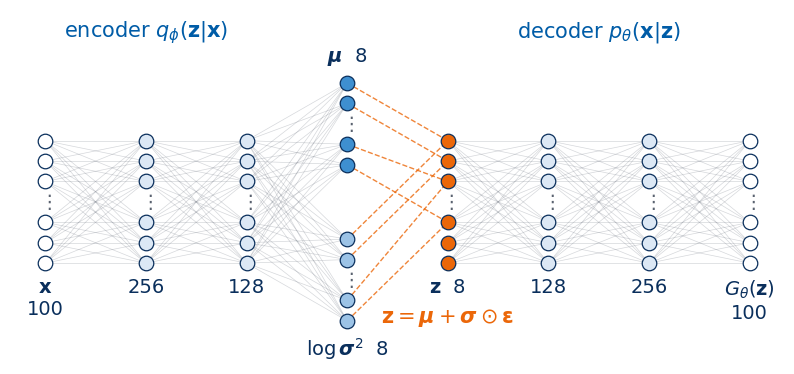

widths read from the model: {'enc': [100, 256, 128], 'd': 8, 'extra': 0, 'dec': [128, 256, 100]}
parameters implied by the drawing: 120,692  =  torchinfo total: 120,692


In [11]:
def linear_widths(model):
    """Layer widths read from the nn.Linear layers of the model: encoder chain, latent size d, inputs added next to z
    (the question of a question-and-answer network), decoder chain."""
    enc = [m for m in model.enc if isinstance(m, nn.Linear)]
    dec = [m for m in model.dec if isinstance(m, nn.Linear)]
    d = model.mu.out_features
    assert model.logvar.out_features == d and model.mu.in_features == model.logvar.in_features == enc[-1].out_features
    return dict(enc=[enc[0].in_features] + [m.out_features for m in enc], d=d, extra=dec[0].in_features - d,
                dec=[m.out_features for m in dec])

def params_from_widths(w):
    """Number of weights and biases implied by the widths (checked against torchinfo)."""
    chain = lambda ws: sum(a * b + b for a, b in zip(ws[:-1], ws[1:]))
    return chain(w["enc"]) + 2 * (w["enc"][-1] * w["d"] + w["d"]) + chain([w["d"] + w["extra"]] + w["dec"])

def draw_network(ax, model, in_label, out_label, extra_label=None, max_nodes=6, dx=1.25, dy=0.34, fs=14):
    """Columns of nodes joined by edges, with every width read from the model. A layer wider than max_nodes (4 in a
    column of two groups) shows that many nodes around a vertical ellipsis, and its label gives the true width.
    mu and log sigma^2 are joined to z one-to-one (dashed): z_k = mu_k + sigma_k eps_k. Returns the widths."""
    w = linear_widths(model)
    cols = ([[dict(n=w["enc"][0], label=f"{in_label}\n{w['enc'][0]}", color="white")]]
            + [[dict(n=n, label=str(n), color=light)] for n in w["enc"][1:]]
            + [[dict(n=w["d"], label=rf"$\boldsymbol{{\mu}}$  {w['d']}", color=sky),
                dict(n=w["d"], label=rf"$\log\boldsymbol{{\sigma}}^2$  {w['d']}", color="#9CC3E6")]]
            + [[dict(n=w["d"], label=rf"$\mathbf{{z}}$  {w['d']}", color=orange, sample=True)]
               + ([dict(n=w["extra"], label=extra_label, color="#F2C14E", no_edges=True)] if w["extra"] else [])]
            + [[dict(n=n, label=str(n), color=light)] for n in w["dec"][:-1]]
            + [[dict(n=w["dec"][-1], label=f"{out_label}\n{w['dec'][-1]}", color="white")]])
    pos = []
    for c, groups in enumerate(cols):
        x = c * dx
        cap = max_nodes if len(groups) == 1 else 4
        shown = [min(gr["n"], cap) for gr in groups]
        heights = [s * dy + (dy if gr["n"] > s else 0) for gr, s in zip(groups, shown)]
        gap = 0.9
        y = (sum(heights) + gap * (len(groups) - 1)) / 2                 # centre the column at y = 0
        col = []
        for gi, (gr, s, h) in enumerate(zip(groups, shown, heights)):
            ys = y - dy / 2 - dy * np.arange(s)
            if gr["n"] > s:                                               # gap with an ellipsis for the hidden nodes
                ys[s // 2:] -= dy
                ax.text(x, (ys[s // 2 - 1] + ys[s // 2]) / 2, r"$\vdots$", ha="center", va="center", fontsize=fs, color=gray)
            ax.scatter(np.full(s, x), ys, s=110, facecolor=gr["color"], edgecolor=navy, lw=0.9, zorder=3)
            if len(groups) == 2 and gi == 0:
                ax.text(x, ys[0] + 0.25, gr["label"], ha="center", va="bottom", fontsize=fs, color=navy)
            else:
                ax.text(x, ys[-1] - 0.25, gr["label"], ha="center", va="top", fontsize=fs, color=navy)
            col.append((gr, ys))
            y -= h + gap
        pos.append((x, col))
    for (x1, left), (x2, right) in zip(pos[:-1], pos[1:]):
        for gr, ysr in right:
            if gr.get("no_edges"):
                continue
            for _, ysl in left:
                if gr.get("sample"):
                    for y1, y2 in zip(ysl, ysr):
                        ax.plot([x1, x2], [y1, y2], color=orange, lw=1.0, ls="--", alpha=0.8, zorder=1)
                else:
                    for y1 in ysl:
                        for y2 in ysr:
                            ax.plot([x1, x2], [y1, y2], color=gray, lw=0.5, alpha=0.25, zorder=1)
    ax.axis("off")
    return w

fig, ax = plt.subplots(figsize=(10, 4.6))
w_vae = draw_network(ax, vae_demo, r"$\mathbf{x}$", r"$G_\theta(\mathbf{z})$")
n_enc = len(w_vae["enc"])
ax.text((n_enc - 1) / 2 * 1.25, 2.75, r"encoder $q_\phi(\mathbf{z}|\mathbf{x})$", ha="center", fontsize=15, color=blue)
ax.text((n_enc + 1 + len(w_vae["dec"]) / 2) * 1.25, 2.75, r"decoder $p_\theta(\mathbf{x}|\mathbf{z})$", ha="center",
        fontsize=15, color=blue)
ax.text((n_enc + 1) * 1.25, -1.75, r"$\mathbf{z}=\boldsymbol{\mu}+\boldsymbol{\sigma}\odot\boldsymbol{\varepsilon}$", ha="center",
        va="top", fontsize=15, color=orange)
ax.set_ylim(-2.7, 3.2)
save_fig(fig, "traj_architecture.png"); plt.show()

n_drawn = params_from_widths(w_vae)
assert n_drawn == stats_vae.total_params == sum(p.numel() for p in vae_demo.parameters())
print("widths read from the model:", w_vae)
print(f"parameters implied by the drawing: {n_drawn:,}  =  torchinfo total: {stats_vae.total_params:,}")
nums["vae_params"] = int(stats_vae.total_params)

The widths read from the model are 100, 256 and 128 in the encoder, 8 for each head and 128, 256 and 100 in the decoder. They imply 120 692 weights and biases, the same number as the torchinfo total. The two layers next to the input and the output, with 25 856 and 25 700 parameters, and the two middle layers of the encoder and the decoder, with 32 896 and 33 024 parameters, hold almost all of them.

### Training

We train all models with the same function, which uses Adam (adaptive moment estimation) with learning rate $10^{-3}$ and minibatches of 128 trajectories. Adam is a gradient method that rescales the step of every parameter by running averages of its gradient and of its squared gradient. If the trained weights were saved by an earlier run, they are loaded and the training is skipped. Setting `TRAIN = True` trains every network again.

We train four values of $\beta$, namely 0.5, 1, 4 and 8, each with three random seeds and for 80 epochs over the 20 000 training trajectories. Several seeds are needed because the outcome of unsupervised disentangling depends on the initialisation [Locatello et al. 2019]. On the 5000 test trajectories we compute the rate and the distortion with one sample $\mathbf z$ per trajectory. As a reference we compute the reconstruction term of the exact mean trajectory,
$$
\Big\langle\frac{1}{2\sigma_x^2}\big\lVert\mathbf x-\langle\mathbf x\rangle\big\rVert^2\Big\rangle, \tag{31}
$$
which is the distortion of a model that knows the four factors perfectly and knows nothing about the noise. We call it the noise floor.

In [12]:
def train(make_model, loss_fn, data, epochs, seed, name, batch_size=128, lr=1e-3, log_every=20):
    """Adam on random minibatches; data = tuple of tensors with the same first dimension.
    Loads the weights from results/name.pt if the file exists (and TRAIN is False); otherwise trains and saves them."""
    torch.manual_seed(seed)
    model = make_model()
    path = f"{RES}/{name}.pt"
    if os.path.exists(path) and not TRAIN:
        ck = torch.load(path, map_location="cpu")
        model.load_state_dict(ck["state"])
        return model.eval(), ck["history"]
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(data[0]); n_batches = n // batch_size
    history, t0 = {}, time.time()
    model.train()
    for ep in range(epochs):
        perm, sums = torch.randperm(n), {}
        for b in range(n_batches):
            idx = perm[b * batch_size:(b + 1) * batch_size]
            loss, aux = loss_fn(model, tuple(a[idx] for a in data))
            opt.zero_grad(); loss.backward(); opt.step()
            for k, v in aux.items():
                sums[k] = sums.get(k, 0.0) + float(v.detach())
        for k, v in sums.items():
            history.setdefault(k, []).append(v / n_batches)
        if (ep + 1) % log_every == 0 or ep + 1 == epochs:
            print(f"  {name} epoch {ep + 1:4d}: " + "  ".join(f"{k} {v[-1]:.3f}" for k, v in history.items())
                  + f"   ({time.time() - t0:5.1f} s)")
    torch.save({"state": model.state_dict(), "history": history}, path)
    return model.eval(), history

def evaluate(model, X, seed=99):
    """Posterior means and log-variances, and the test rate R and distortion (nats per trajectory, one sample z)."""
    Xt = torch.as_tensor(X)
    with torch.no_grad():
        mu, lv = model.encode(Xt)
        eps = torch.randn(mu.shape, generator=torch.Generator().manual_seed(seed))
        rec = ((model.decode(mu + torch.exp(0.5 * lv) * eps) - Xt) ** 2).sum(1) / (2 * SIGMA_X**2)
    mu, lv = mu.numpy(), lv.numpy()
    return mu, lv, float(kl_per_dim(mu, lv).sum(1).mean()), float(rec.mean())

def decode(model, Z):
    with torch.no_grad():
        return model.decode(torch.as_tensor(np.asarray(Z, np.float32))).numpy()

In [13]:
BETAS, SEEDS, EPOCHS = [0.5, 1, 4, 8], [0, 1, 2], 80
Xtr_t = torch.as_tensor(Xtr)
t0 = time.time()
vaes = {}
for beta in BETAS:
    for s in SEEDS:
        vaes[beta, s], _ = train(lambda: TrajVAE(T_POINTS, D_LATENT), partial(beta_vae_loss, beta=beta), (Xtr_t,), EPOCHS, s,
                                 name=f"traj_osc_beta{beta}_seed{s}")
print(f"{len(vaes)} models ready in {time.time() - t0:.0f} s")

ev = {key: evaluate(m, Xte) for key, m in vaes.items()}
floor = ((dev**2).sum(-1) / (2 * SIGMA_X**2)).mean()
print(f"reconstruction term of the exact mean trajectory (noise floor): {floor:.2f} nats")
print("beta  seed   rate R   distortion")
for (beta, s), (_, _, R, Drec) in ev.items():
    print(f"{beta:4}  {s:4}  {R:7.2f}  {Drec:9.2f}")
nums["noise_floor"] = float(floor)
nums["rate_distortion"] = {f"{b}_{s}": [round(ev[b, s][2], 3), round(ev[b, s][3], 3)] for b, s in ev}

  traj_osc_beta0.5_seed0 epoch   20: loss 7.909  rec 2.565  kl 10.688   ( 34.6 s)


  traj_osc_beta0.5_seed0 epoch   40: loss 7.301  rec 2.256  kl 10.091   ( 68.7 s)


  traj_osc_beta0.5_seed0 epoch   60: loss 7.210  rec 2.275  kl 9.870   ( 99.0 s)


  traj_osc_beta0.5_seed0 epoch   80: loss 7.069  rec 2.182  kl 9.774   (132.5 s)


  traj_osc_beta0.5_seed1 epoch   20: loss 7.938  rec 2.612  kl 10.652   ( 30.1 s)


...

  traj_osc_beta8_seed2 epoch   20: loss 54.796  rec 17.335  kl 4.683   (225.5 s)


  traj_osc_beta8_seed2 epoch   40: loss 53.882  rec 16.575  kl 4.663   (462.8 s)


  traj_osc_beta8_seed2 epoch   60: loss 53.443  rec 16.281  kl 4.645   (699.2 s)


  traj_osc_beta8_seed2 epoch   80: loss 53.217  rec 15.954  kl 4.658   (920.1 s)
12 models ready in 9276 s


reconstruction term of the exact mean trajectory (noise floor): 4.96 nats
beta  seed   rate R   distortion
 0.5     0     9.69       2.21
 0.5     1     9.94       2.33
 0.5     2    10.11       2.00
   1     0     8.28       3.45
   1     1     8.50       3.63
   1     2     8.53       3.01
   4     0     5.85       9.30
   4     1     5.87       9.47
   4     2     5.79       9.27
   8     0     4.61      16.37
   8     1     4.76      15.46
   8     2     4.68      16.25


The rate falls and the distortion grows with $\beta$, as in Lecture 6. At $\beta=0.5$ the rate lies between 9.69 and 10.11 nats and the distortion between 2.00 and 2.33 nats, and at $\beta=8$ the rate lies between 4.61 and 4.76 nats and the distortion between 15.46 and 16.37 nats. The three seeds of each $\beta$ agree to a few tenths of a nat in the rate. For $\beta$ of 0.5 and 1 the distortion (2.00 to 3.63 nats) lies below the noise floor of 4.96 nats. The decoder then reproduces part of the deviation of the individual trajectory from its mean, which it can do only if the code stores information about that particular realisation of the noise. The deviation caused by the random force is correlated in time, so a few nats describe a good part of it. For $\beta$ of 4 and 8 the distortion (9.27 to 16.37 nats) lies above the floor, and the code describes smooth trajectories.

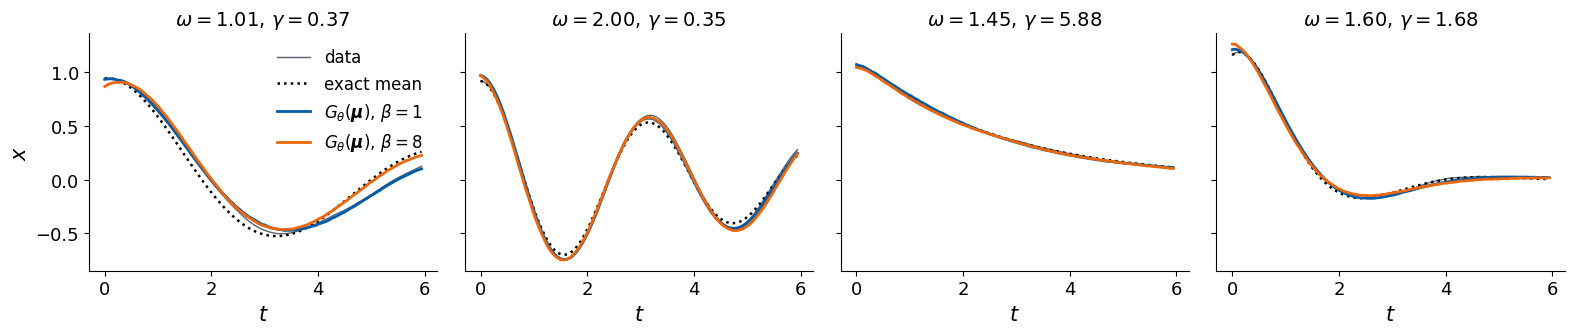

factors (omega, gamma, x0, v0) of the four examples: [(np.float64(1.01), np.float64(0.37), np.float64(0.94), np.float64(0.04)), (np.float64(2.0), np.float64(0.35), np.float64(0.92), np.float64(-0.06)), (np.float64(1.45), np.float64(5.88), np.float64(1.05), np.float64(-0.03)), (np.float64(1.6), np.float64(1.68), np.float64(1.16), np.float64(0.43))]


In [14]:
show_i = [sel_w[0], sel_w[-1], sel_g[-1], int(np.flatnonzero(near(3, 0.4, 0.5))[0])]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for a, i in zip(axs, show_i):
    a.plot(t_grid, Xte[i], color=gray, lw=1, label="data")
    a.plot(t_grid, Mte[i], ":", color="k", lw=1.8, label="exact mean")
    for beta, col in [(1, blue), (8, orange)]:
        a.plot(t_grid, decode(vaes[beta, 0], ev[beta, 0][0][i:i + 1])[0], color=col, label=rf"$G_\theta(\boldsymbol{{\mu}})$, $\beta={beta}$")
    a.set_title(rf"$\omega={Fte[i, 0]:.2f}$, $\gamma={Fte[i, 1]:.2f}$", fontsize=14); a.set_xlabel("$t$")
axs[0].set_ylabel("$x$"); axs[0].legend(fontsize=12)
plt.tight_layout(); plt.show()
print("factors (omega, gamma, x0, v0) of the four examples:", [tuple(np.round(Fte[i], 2)) for i in show_i])

The examples cover a slow and a fast underdamped oscillation, an overdamped creep and a trajectory with a large initial velocity. At $\beta=1$ and at $\beta=8$ the reconstructions $G_\theta(\boldsymbol\mu)$ are smooth curves close to the exact mean trajectory (dotted), and by eye the two values of $\beta$ differ only slightly, mostly at late times of the slowest oscillation. The rate and the distortion in the table are the more sensitive measure.

## Latent coordinates and physical parameters

We read the latent codes with the protocol of Lecture 6. We first find the coordinates that carry information, then compare them with the known factors through correlations and the mutual information gap, then decode traversals, and finally explain the outcome by the physics of the trajectories.

### Active coordinates

A coordinate whose posterior equals the prior for every trajectory carries no information. Its average KL over the test trajectories,
$$
\overline{\mathrm{KL}}_k=\Big\langle\tfrac12\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)\Big\rangle_{\mathbf x}, \tag{32}
$$
measures in nats how much coordinate $k$ is used. As in Lecture 6, we call a coordinate active if its average KL exceeds 0.1 nats.

In [15]:
ACTIVE_NATS = 0.1
kl_dims = {key: kl_per_dim(e[0], e[1]).mean(0) for key, e in ev.items()}
active = {key: np.flatnonzero(k > ACTIVE_NATS) for key, k in kl_dims.items()}
print("mean KL per coordinate (nats), sorted; active coordinates:")
for key in vaes:
    print(f"beta {key[0]:3}, seed {key[1]}:", np.round(np.sort(kl_dims[key])[::-1], 2), "  active:", len(active[key]))
nums["n_active"] = {str(b): [int(len(active[b, s])) for s in SEEDS] for b in BETAS}

mean KL per coordinate (nats), sorted; active coordinates:
beta 0.5, seed 0: [3.5  2.7  2.48 1.   0.   0.   0.   0.  ]   active: 4
beta 0.5, seed 1: [3.41 3.22 2.24 1.08 0.   0.   0.   0.  ]   active: 4
beta 0.5, seed 2: [3.54 3.25 2.26 1.06 0.   0.   0.   0.  ]   active: 4
beta   1, seed 0: [3.21 2.25 2.12 0.69 0.   0.   0.   0.  ]   active: 4
beta   1, seed 1: [3.15 2.97 1.68 0.7  0.   0.   0.   0.  ]   active: 4
beta   1, seed 2: [3.29 2.88 1.66 0.71 0.   0.   0.   0.  ]   active: 4
beta   4, seed 0: [2.65 2.08 0.92 0.2  0.   0.   0.   0.  ]   active: 4
beta   4, seed 1: [2.46 2.25 0.93 0.22 0.   0.   0.   0.  ]   active: 4
beta   4, seed 2: [2.65 2.05 0.87 0.22 0.   0.   0.   0.  ]   active: 4
beta   8, seed 0: [2.28 1.71 0.62 0.   0.   0.   0.   0.  ]   active: 3
beta   8, seed 1: [2.38 1.73 0.65 0.   0.   0.   0.   0.  ]   active: 3
beta   8, seed 2: [2.32 1.73 0.61 0.01 0.   0.   0.   0.  ]   active: 3


The number of active coordinates is four for $\beta$ of 0.5, 1 and 4 in all three seeds, and three for $\beta=8$. All other coordinates carry at most 0.01 nats and are switched off. Without being told, the network thus uses as many coordinates as there are factors, four, over a wide range of $\beta$. At $\beta=4$ the weakest active coordinate keeps only 0.20 to 0.22 nats, and at $\beta=8$ it drops to 0.00 to 0.01 nats, below the threshold. One factor has then been dropped, and the correlations show which one.

### Correlations

The first probe is the Pearson correlation between the latent mean $\mu_k(\mathbf x)$ and a factor $v$ over the test set,
$$
\rho(\mu_k,v)=\frac{\langle\mu_kv\rangle-\langle\mu_k\rangle\langle v\rangle}{\sqrt{\mathrm{Var}\,\mu_k\;\mathrm{Var}\,v}}. \tag{33}
$$
It lies between $-1$ and 1 and detects linear relations only. The friction enters as $\ln\gamma$, because $\gamma$ spans a factor of 30 and is drawn uniformly in $\ln\gamma$. The sign of a latent coordinate is arbitrary, so we report $|\rho|$.

### Entropy, mutual information and the gap

The second probe is the mutual information gap (MIG) of [Chen et al. (2018)](https://arxiv.org/abs/1802.04942), also used in Lecture 6, which detects nonlinear relations as well. It is built from two quantities of information theory, both of them expectations of logarithms of probabilities like the KL divergence (28) of the loss.

The entropy of a factor measures how uncertain its value is before anything is observed. An outcome $b$ of probability $p(b)$ carries the surprise $-\ln p(b)$, which is zero for a certain outcome and large for a rare one. The entropy is the average surprise,
$$
H(v)=-\sum_b p(b)\ln p(b), \tag{34}
$$
measured in nats. For a variable with $n$ equally likely values it equals $\ln n$, and it grows with the number of values that have to be told apart. The factors of the trajectories are continuous, so we discretise each of them into 20 bins of equal population, with the bin edges at the quantiles of the factor over the test set. Every bin then holds 5% of the test trajectories, and the entropy of each discretised factor is $\ln20$, about 3.00 nats. In this description the frequency, the damping and the two initial values are equally uncertain, whatever their physical units. The printed entropies confirm the value.

The mutual information of a latent coordinate $z$ and a factor $v$ measures how much of this uncertainty disappears once $z$ is known. It is the entropy of the factor minus the conditional entropy $H(v|z)$, the uncertainty about the factor that remains after reading the coordinate. It can also be written as the KL divergence between the joint distribution of the two variables and the product of their marginal distributions, which is the joint distribution they would have if they were independent,
$$
I(z;v)=H(v)-H(v|z)=\sum_{a,b}p(a,b)\,\ln\frac{p(a,b)}{p(a)\,p(b)}=\mathrm{KL}\big(p(z,v)\,\|\,p(z)\,p(v)\big). \tag{35}
$$
The mutual information is zero when the coordinate and the factor are independent, and it reaches $H(v)$ when the coordinate determines the factor completely. The correlation (33) misses relations that are not linear, and the mutual information detects them, for example a coordinate that grows with the frequency for small initial positions and falls for large ones. Since the mutual information cannot exceed the entropy of the factor, the normalised mutual information
$$
\tilde I(z;v)=\frac{I(z;v)}{H(v)} \tag{36}
$$
lies between 0, when the coordinate says nothing about the factor, and 1, when it determines the factor. We read it as the fraction of the uncertainty about the factor that the coordinate removes.

The MIG condenses the matrix of normalised mutual informations into one number. For each factor $v_k$ it takes the normalised mutual information of the most informative coordinate $z_{(1)}$ minus that of the second most informative coordinate $z_{(2)}$, and it averages these gaps over the $K$ factors, here four,
$$
\mathrm{MIG}=\frac1K\sum_{k=1}^{K}\Big[\tilde I\big(z_{(1)};v_k\big)-\tilde I\big(z_{(2)};v_k\big)\Big]. \tag{37}
$$
A factor captured by one coordinate scores close to its normalised mutual information. A factor smeared over two coordinates, say with 0.35 and 0.30, scores 0.05 even if the representation contains it completely. A factor copied into two coordinates, with 0.60 and 0.60, scores zero, although a score based on the largest value alone would reward it. The gap therefore rewards one coordinate per factor, and only one, which is what disentanglement asks for.

We estimate these quantities from histograms. For every active coordinate we put the posterior means $\mu_k$ of the 5000 test trajectories into 20 bins of equal width between their smallest and largest value. Every factor ($\omega$, $\ln\gamma$, $x_0$ and $v_0$) goes into the 20 equal-population bins described earlier. The probabilities in equations (34) and (35) are the frequencies of the bins and of the $20\times20$ pairs of bins. Only active coordinates enter, because an inactive coordinate passes no information to the decoder, and a factor with fewer than two active coordinates is compared with zero for the missing ones. Chen et al. estimate the mutual information by sampling from $q_\phi(\mathbf z|\mathbf x)$, and the binned means are a common simplification. With 20 bins the estimator is biased, and even a perfect code stays below 1 because the bins of the latent means and of the factors do not coincide. We therefore also evaluate the MIG for the true factors used as a code, and for the factors with $\omega$ and $x_0$ mixed by a rotation of $45^\circ$. These two values set the scale between a perfect and a half-mixed code. We also compare one mutual information with `mutual_info_score` of scikit-learn.

In [16]:
def abs_corr(mu, P):
    """|Pearson correlation| between every latent mean (columns of mu) and every factor (columns of P): (d, K)."""
    d = mu.shape[1]
    return np.nan_to_num(np.abs(np.corrcoef(np.c_[mu, P].T)[:d, d:]))

N_BINS = 20
def bins_equal_width(v):
    return np.clip(((v - v.min()) / (v.max() - v.min() + 1e-12) * N_BINS).astype(int), 0, N_BINS - 1)
def bins_quantile(v):
    return np.searchsorted(np.quantile(v, np.linspace(0, 1, N_BINS + 1)[1:-1]), v)
def entropy(labels):
    p = np.bincount(labels) / len(labels); p = p[p > 0]
    return float(-(p * np.log(p)).sum())
def mutual_information(a, b):
    return entropy(a) + entropy(b) - entropy(a * N_BINS + b)

def mig(mu, P, act):
    """Mutual information gap per factor; latent means of the active coordinates in 20 equal-width bins,
    factors in 20 equal-population bins (entropy ln 20)."""
    zb = [bins_equal_width(mu[:, j]) for j in act]
    gaps = []
    for k in range(P.shape[1]):
        vb = bins_quantile(P[:, k])
        I = sorted([mutual_information(z, vb) for z in zb] + [0.0, 0.0], reverse=True)
        gaps.append((I[0] - I[1]) / entropy(vb))
    return np.array(gaps)

H_fac = [entropy(bins_quantile(Pte[:, k])) for k in range(4)]
print("entropies of the discretised factors (omega, ln gamma, x0, v0), nats:", np.round(H_fac, 4), f"  ln 20 = {np.log(20):.4f}")
print("entropy of the 20 equal-width bins of each active latent mean, beta = 4, seed 0 (nats):",
      np.round([entropy(bins_equal_width(ev[4, 0][0][:, j])) for j in active[4, 0]], 2))
corr = {key: abs_corr(ev[key][0], Pte) for key in vaes}
migs = {key: mig(ev[key][0], Pte, active[key]) for key in vaes}
print("MIG per factor (omega, ln gamma, x0, v0) and mean:")
for key in vaes:
    print(f"beta {key[0]:3}, seed {key[1]}:", np.round(migs[key], 3), f"  mean {migs[key].mean():.3f}")

# the estimator on the factors themselves, and on the factors with omega and x0 mixed by a rotation of 45 degrees
P_rot = Pte.copy(); s_ = (Pte - Pte.mean(0)) / Pte.std(0)
P_rot[:, 0], P_rot[:, 2] = (s_[:, 0] + s_[:, 2]) / np.sqrt(2), (s_[:, 0] - s_[:, 2]) / np.sqrt(2)
print(f"MIG of the true factors: {mig(Pte, Pte, range(4)).mean():.3f};  omega and x0 rotated by 45 degrees: "
      f"{mig(P_rot, Pte, range(4)).mean():.3f}")

# the same mutual information with scikit-learn (natural logarithm, nats)
j0 = active[4, 0][0]
a_, b_ = bins_equal_width(ev[4, 0][0][:, j0]), bins_quantile(Pte[:, 1])
print(f"I(mu_{j0}; ln gamma), beta = 4, seed 0: own estimator {mutual_information(a_, b_):.6f} nats, "
      f"sklearn mutual_info_score {mutual_info_score(a_, b_):.6f} nats")
nums["mig"] = {str(b): [float(migs[b, s].mean()) for s in SEEDS] for b in BETAS}
nums["mig_true"] = float(mig(Pte, Pte, range(4)).mean()); nums["mig_rot"] = float(mig(P_rot, Pte, range(4)).mean())

entropies of the discretised factors (omega, ln gamma, x0, v0), nats: [2.9957 2.9957 2.9957 2.9957]   ln 20 = 2.9957
entropy of the 20 equal-width bins of each active latent mean, beta = 4, seed 0 (nats): [2.45 2.57 2.02 2.66]


MIG per factor (omega, ln gamma, x0, v0) and mean:
beta 0.5, seed 0: [0.11  0.129 0.172 0.082]   mean 0.123
beta 0.5, seed 1: [0.006 0.121 0.08  0.09 ]   mean 0.074
beta 0.5, seed 2: [0.02  0.094 0.107 0.098]   mean 0.080
beta   1, seed 0: [0.132 0.143 0.154 0.09 ]   mean 0.130
beta   1, seed 1: [0.011 0.128 0.092 0.096]   mean 0.082
beta   1, seed 2: [0.042 0.107 0.073 0.103]   mean 0.081
beta   4, seed 0: [0.05  0.073 0.027 0.057]   mean 0.052
beta   4, seed 1: [0.021 0.069 0.024 0.06 ]   mean 0.043
beta   4, seed 2: [0.041 0.044 0.015 0.061]   mean 0.040
beta   8, seed 0: [0.052 0.103 0.018 0.002]   mean 0.044
beta   8, seed 1: [0.047 0.104 0.023 0.001]   mean 0.044
beta   8, seed 2: [0.048 0.105 0.011 0.003]   mean 0.042
MIG of the true factors: 0.916;  omega and x0 rotated by 45 degrees: 0.462
I(mu_1; ln gamma), beta = 4, seed 0: own estimator 0.285115 nats, sklearn mutual_info_score 0.285115 nats


The printed entropies of the four discretised factors are all 2.9957 nats, which is $\ln20$, as the equal-population bins require. The binned latent means have smaller entropies, between 2.02 and 2.66 nats for the model with $\beta=4$ and seed 0, because their histograms are peaked near zero. The mutual information of the first active coordinate with $\ln\gamma$ in this model is 0.285115 nats with our estimator and with `mutual_info_score`, so the two implementations agree.

The estimator gives a MIG of 0.916 for the true factors, below 1 because of the binning, and 0.462 when $\omega$ and $x_0$ are mixed by the rotation. Mixing two of the four factors thus roughly halves the score. All twelve models lie between 0.040 and 0.130, far below even the rotated code.

model shown: beta = 4, seed = 0 (largest MIG of the three seeds)
mean KL of the active coordinates (nats): {'z_6': 2.65, 'z_2': 2.08, 'z_1': 0.92, 'z_3': 0.2}
|corr|, rows: active coordinates by decreasing KL; columns: omega, ln gamma, x0, v0
[[0.4  0.84 0.06 0.09]
 [0.49 0.22 0.46 0.23]
 [0.42 0.36 0.59 0.06]
 [0.08 0.05 0.26 0.55]]
normalised mutual information I/H, same rows and columns:
[[0.05 0.22 0.06 0.02]
 [0.1  0.05 0.07 0.02]
 [0.05 0.1  0.09 0.02]
 [0.02 0.15 0.03 0.08]]


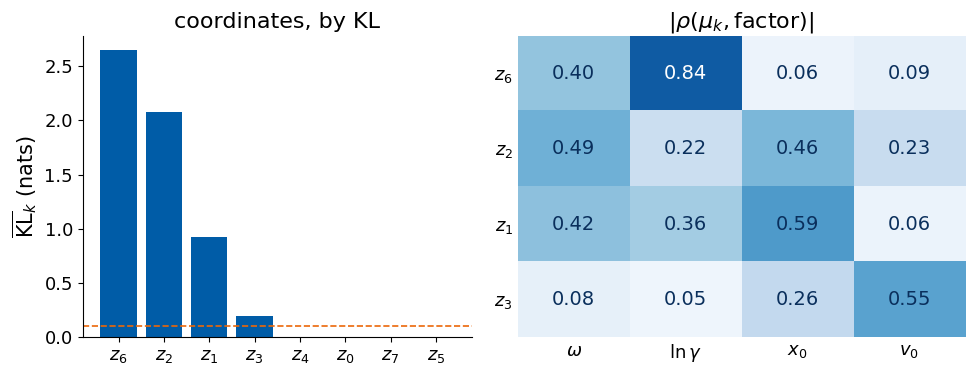

omega-coordinate z_2, gamma-coordinate z_6, x0-coordinate z_1


In [17]:
SHOW_BETA = 4
show_seed = max(SEEDS, key=lambda s: migs[SHOW_BETA, s].mean())
key_show = (SHOW_BETA, show_seed)
act_show = active[key_show][np.argsort(kl_dims[key_show][active[key_show]])[::-1]]   # active, by decreasing KL
print(f"model shown: beta = {SHOW_BETA}, seed = {show_seed} (largest MIG of the three seeds)")
print("mean KL of the active coordinates (nats):", {f"z_{k}": round(float(kl_dims[key_show][k]), 2) for k in act_show})
print("|corr|, rows: active coordinates by decreasing KL; columns: omega, ln gamma, x0, v0")
print(np.round(corr[key_show][act_show], 2))
nmi_show = np.array([[mutual_information(bins_equal_width(ev[key_show][0][:, j]), bins_quantile(Pte[:, k])) / H_fac[k]
                      for k in range(4)] for j in act_show])
print("normalised mutual information I/H, same rows and columns:")
print(np.round(nmi_show, 2))
nums["show_nmi"] = np.round(nmi_show, 3).tolist()

fig, axs = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw=dict(width_ratios=[1, 1.15]))
order = np.argsort(kl_dims[key_show])[::-1]
axs[0].bar(np.arange(D_LATENT), kl_dims[key_show][order], color=[blue if k in act_show else gray for k in order])
axs[0].axhline(ACTIVE_NATS, color=orange, lw=1.2, ls="--")
axs[0].set_xticks(np.arange(D_LATENT)); axs[0].set_xticklabels([f"$z_{k}$" for k in order])
axs[0].set_ylabel(r"$\overline{\mathrm{KL}}_k$ (nats)"); axs[0].set_title("coordinates, by KL")
C_show = corr[key_show][act_show]
axs[1].imshow(C_show, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(C_show):
    axs[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=14, color="white" if v > 0.6 else navy)
axs[1].set_xticks(range(4)); axs[1].set_xticklabels(FACTOR_NAMES)
axs[1].set_yticks(range(len(act_show))); axs[1].set_yticklabels([f"$z_{k}$" for k in act_show])
axs[1].set_title(r"$|\rho(\mu_k,\mathrm{factor})|$")
axs[1].spines[:].set_visible(False); axs[1].tick_params(length=0)
plt.tight_layout(); save_fig(fig, "traj_corr.png"); plt.show()

k_w = act_show[np.argmax(corr[key_show][act_show, 0])]      # coordinate most correlated with omega
k_g = act_show[np.argmax(corr[key_show][act_show, 1])]      # ... with ln gamma
k_x = act_show[np.argmax(corr[key_show][act_show, 2])]      # ... with x0
print(f"omega-coordinate z_{k_w}, gamma-coordinate z_{k_g}, x0-coordinate z_{k_x}")
nums["show"] = {"beta": SHOW_BETA, "seed": int(show_seed), "active": [int(k) for k in act_show],
                "corr": np.round(corr[key_show][act_show], 3).tolist(), "k_w": int(k_w), "k_g": int(k_g), "k_x": int(k_x)}

The figure shows the model with $\beta=4$ whose MIG is the largest of its three seeds, seed 0 with 0.052. Choosing it requires the true factors, which an experiment without ground truth would not have, and the next section summarises all models. The four active coordinates read as follows. The most informative coordinate $z_6$ (2.65 nats) follows $\ln\gamma$ with $|\rho|$ of 0.84, and its correlation with $\omega$ is 0.40 and with the initial values below 0.1. We call it the damping coordinate. The coordinate $z_2$ (2.08 nats) correlates with $\omega$ (0.49) and with $x_0$ (0.46), and $z_1$ (0.92 nats) with $x_0$ (0.59), $\omega$ (0.42) and $\ln\gamma$ (0.36). The weakest coordinate $z_3$ (0.20 nats) follows $v_0$ (0.55). Each factor has a coordinate in which it is the largest entry, so the code assigns roughly one coordinate per factor, but only the damping is separated well. The frequency and the initial position are shared between $z_2$ and $z_1$.

The normalised mutual informations are small for all pairs. The largest is 0.22 for $z_6$ and $\ln\gamma$, and the next largest values are 0.15, 0.10 and 0.10. The value 0.15 belongs to $z_3$ and $\ln\gamma$, a pair whose correlation is only 0.05, so this dependence is nonlinear. A value of 0.22 means that reading $z_6$ removes about a fifth of the uncertainty about which of the 20 friction bins a trajectory belongs to.

### Disentangling and β

The figure summarises all twelve models. The left panel shows, for each factor, the largest $|\rho|$ over the active coordinates, averaged over the three seeds, with a band from the smallest to the largest seed. The right panel shows the gap of each factor and their mean, the MIG.

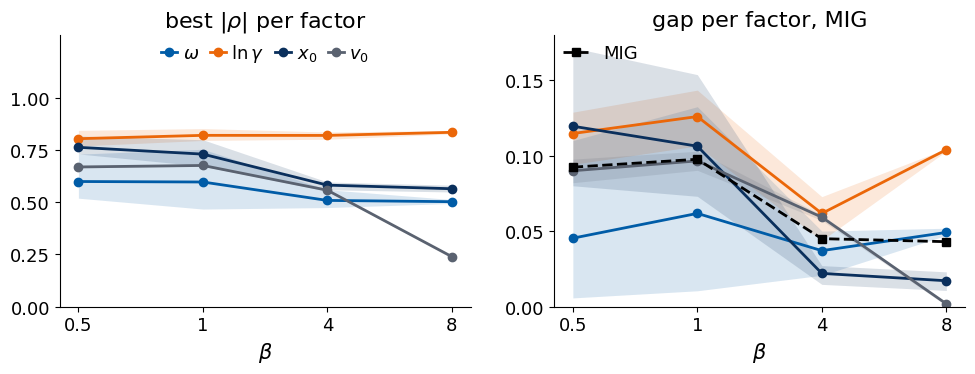

best |rho| per factor (omega, ln gamma, x0, v0), mean over seeds:
  beta 0.5: mean [0.6  0.8  0.76 0.67],  min [0.52 0.77 0.73 0.66],  max [0.73 0.84 0.82 0.67],  MIG mean 0.092
  beta   1: mean [0.6  0.82 0.73 0.68],  min [0.47 0.8  0.67 0.67],  max [0.75 0.85 0.8  0.68],  MIG mean 0.098
  beta   4: mean [0.51 0.82 0.58 0.56],  min [0.47 0.8  0.56 0.55],  max [0.56 0.84 0.6  0.56],  MIG mean 0.045
  beta   8: mean [0.5  0.83 0.56 0.24],  min [0.49 0.83 0.55 0.23],  max [0.51 0.84 0.58 0.24],  MIG mean 0.043


In [18]:
best_corr = {key: corr[key][active[key]].max(0) if len(active[key]) else np.zeros(4) for key in vaes}
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
cols = [blue, orange, navy, gray]
xb = np.arange(len(BETAS))
for k in range(4):
    m = np.array([[best_corr[b, s][k] for s in SEEDS] for b in BETAS])
    axs[0].plot(xb, m.mean(1), "o-", color=cols[k], label=FACTOR_NAMES[k], ms=6)
    axs[0].fill_between(xb, m.min(1), m.max(1), color=cols[k], alpha=0.15, lw=0)
    gk = np.array([[migs[b, s][k] for s in SEEDS] for b in BETAS])
    axs[1].plot(xb, gk.mean(1), "o-", color=cols[k], ms=6)
    axs[1].fill_between(xb, gk.min(1), gk.max(1), color=cols[k], alpha=0.15, lw=0)
m_all = np.array([[migs[b, s].mean() for s in SEEDS] for b in BETAS])
axs[1].plot(xb, m_all.mean(1), "s--", color="k", ms=6, label="MIG")
for a in axs:
    a.set_xticks(xb); a.set_xticklabels([f"{b:g}" for b in BETAS]); a.set_xlabel(r"$\beta$")
axs[0].set_ylim(0, 1.3); axs[0].set_yticks([0, 0.25, 0.5, 0.75, 1]); axs[0].set_title(r"best $|\rho|$ per factor")
axs[1].set_title("gap per factor, MIG"); axs[1].set_ylim(0, None)
axs[0].legend(loc="upper center", ncol=4, handlelength=0.9, columnspacing=0.6, handletextpad=0.3, borderaxespad=0.0)
axs[1].legend(loc="upper left", handlelength=1.4, borderaxespad=0.1)
plt.tight_layout(); save_fig(fig, "traj_mig_beta.png"); plt.show()
print("best |rho| per factor (omega, ln gamma, x0, v0), mean over seeds:")
for b in BETAS:
    mb = np.array([best_corr[b, s] for s in SEEDS])
    print(f"  beta {b:3}: mean {np.round(mb.mean(0), 2)},  min {np.round(mb.min(0), 2)},  max {np.round(mb.max(0), 2)},"
          f"  MIG mean {m_all[BETAS.index(b)].mean():.3f}")
nums["best_corr_mean"] = {str(b): np.mean([best_corr[b, s] for s in SEEDS], 0).round(3).tolist() for b in BETAS}

Over all models the damping is the factor found best. Averaged over the seeds its largest $|\rho|$ lies between 0.80 and 0.83 for every $\beta$, with a narrow band from 0.77 to 0.85 over the seeds. The frequency stays between 0.50 and 0.60. The initial position reaches 0.76 at $\beta=0.5$ and falls to 0.56 at $\beta=8$. The initial velocity keeps 0.56 to 0.68 up to $\beta=4$ and drops to 0.24 at $\beta=8$, so it is the factor that the strongest pressure switches off. The MIG averaged over the seeds is 0.092, 0.098, 0.045 and 0.043 for $\beta$ of 0.5, 1, 4 and 8. No value of $\beta$ gives a disentangled code, and increasing $\beta$ beyond 1 lowers the MIG here. A larger $\beta$ removes the factor that is least visible in the data and reduces the information about the others. At $\beta=1$ the seeds give 0.130, 0.082 and 0.081, so the spread between seeds is comparable to the change with $\beta$, as Locatello et al. observed in their large study.

### Latent traversals

Correlations are computed from the encoder, and a traversal probes the decoder. We start from the latent mean $\boldsymbol\mu$ of one test trajectory, set one active coordinate to a value $\delta$ while keeping the others, and decode the latent vector
$$
\mathbf z(\delta)=\boldsymbol\mu+(\delta-\mu_k)\,\mathbf e_k, \tag{38}
$$
where $\mathbf e_k$ is the unit vector along coordinate $k$ and $\delta$ runs from $-2.5$ to 2.5, two and a half prior standard deviations on each side. The reference trajectory is the test trajectory closest to $\omega=1.5$, $\gamma=1$, $x_0=1$ and $v_0=0$. The title of each panel names the factor with the largest $|\rho|$ for that coordinate.

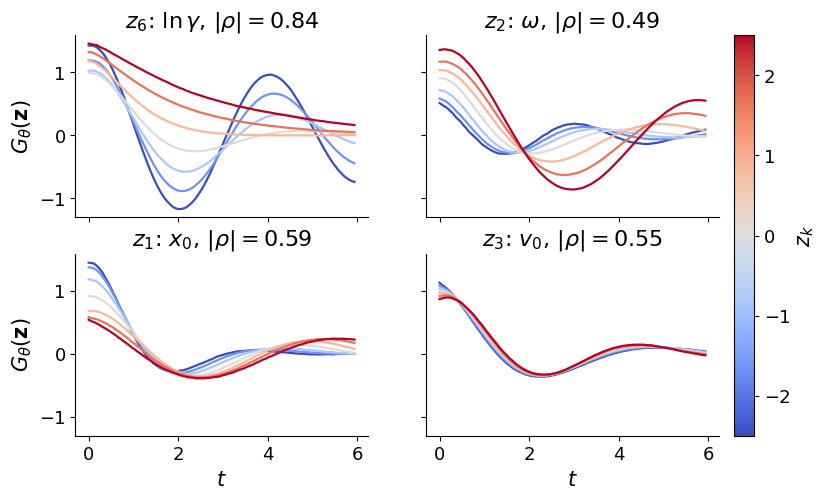

reference trajectory: omega = 1.48, gamma = 1.06, x0 = 1.01, v0 = -0.01
its latent means on the active coordinates: {'z_6': -0.24, 'z_2': 0.45, 'z_1': -0.22, 'z_3': 0.17}


In [19]:
ref = int(np.argmin(((Pte - np.array([1.5, 0.0, 1.0, 0.0])) / Pte.std(0)) ** 2 @ np.ones(4)))
mu_ref = ev[key_show][0][ref]
z_vals = np.linspace(-2.5, 2.5, 7)
trav_coords = list(act_show[:4])
nr = int(np.ceil(len(trav_coords) / 2))
fig, axs = plt.subplots(nr, 2, figsize=(10, 2.4 * nr + 0.4), sharex=True, sharey=True, squeeze=False)
for a, k in zip(axs.ravel(), trav_coords):
    Z = np.repeat(mu_ref[None], len(z_vals), 0); Z[:, k] = z_vals
    for v, cv in zip(z_vals, decode(vaes[key_show], Z)):
        a.plot(t_grid, cv, color=plt.cm.coolwarm((v + 2.5) / 5), lw=1.6)
    f = int(np.argmax(corr[key_show][k]))
    a.set_title(rf"$z_{k}$: {FACTOR_NAMES[f]}, $|\rho|={corr[key_show][k, f]:.2f}$")
for a in axs.ravel()[len(trav_coords):]:
    a.axis("off")
for a in axs[-1]: a.set_xlabel("$t$")
for a in axs[:, 0]: a.set_ylabel(r"$G_\theta(\mathbf{z})$")
cb = fig.colorbar(plt.cm.ScalarMappable(Normalize(-2.5, 2.5), "coolwarm"), ax=axs, pad=0.02, aspect=20)
cb.set_label("$z_k$")
save_fig(fig, "traj_traversals.png"); plt.show()
print("reference trajectory: omega = %.2f, gamma = %.2f, x0 = %.2f, v0 = %.2f" % tuple(Fte[ref]))
print("its latent means on the active coordinates:", {f"z_{k}": round(float(mu_ref[k]), 2) for k in act_show})

The traversals confirm the reading of the correlations and show what the numbers hide. Moving $z_6$ turns a damped oscillation with a deep first minimum into an overdamped creep, which is the effect of the damping. Moving $z_2$ changes the period of the decoded oscillation, with the first minimum shifting from about $t=1.5$ to about $t=3$, and it changes the starting value $x(0)$ from about 0.5 to about 1.35 at the same time. Moving $z_1$ changes the initial position from about 1.45 to about 0.55 together with the phase of the later oscillation. Moving $z_3$ changes the trajectory only slightly, mostly its slope near $t=0$, as expected for a coordinate with 0.20 nats that follows the initial velocity.

### Frequency and damping coordinates

A correlation coefficient compresses a cloud of points into one number, and scatter plots show the clouds themselves. We plot the coordinate most correlated with $\omega$ against $\omega$, coloured by $x_0$, and the coordinate most correlated with $\ln\gamma$ against $\ln\gamma$, coloured by the regime. We measure how much of the variance of the frequency coordinate $y$ a least-squares fit $\hat y$ with a given set of factors explains by the coefficient of determination
$$
R^2=1-\frac{\mathrm{Var}(y-\hat y)}{\mathrm{Var}\,y}, \tag{39}
$$
which is 1 for a perfect fit and 0 for a fit no better than a constant. We compute it with a least-squares solver and check it with `LinearRegression` of scikit-learn. We also compute the correlations separately in the underdamped and in the overdamped regime, where equation (10) predicts that only $\omega^2/\gamma$ matters.

R^2 of the omega-coordinate z_2 explained by:
  omega                                                   0.241
  omega, x0                                               0.449
  omega, x0, omega*x0                                     0.471
  omega, ln gamma, x0, v0 (all, + squares and products)   0.969
the same last fit with scikit-learn LinearRegression: R^2 = 0.969


underdamped  (3932 test trajectories): |rho(z_6, ln gamma)| = 0.74, |rho(z_2, omega)| = 0.73, |rho(z_6, ln(omega^2/gamma))| = 0.88, |rho(z_2, ln(omega^2/gamma))| = 0.26
overdamped   (1068 test trajectories): |rho(z_6, ln gamma)| = 0.12, |rho(z_2, omega)| = 0.26, |rho(z_6, ln(omega^2/gamma))| = 0.66, |rho(z_2, ln(omega^2/gamma))| = 0.46


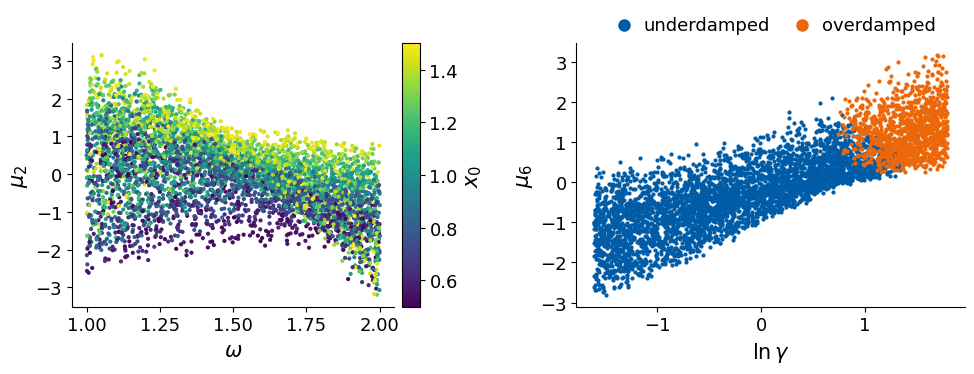

In [20]:
mu_s = ev[key_show][0]
def r2(y, cols):
    """Fraction of the variance of y explained by a least-squares fit with the given columns (and a constant)."""
    A = np.c_[np.ones(len(y)), *cols]
    res = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return 1 - res.var() / y.var()
w_, lg_, x0_ = Pte[:, 0], Pte[:, 1], Pte[:, 2]
all_terms = [Pte[:, i] * Pte[:, j] for i in range(4) for j in range(i, 4)] + [Pte[:, i] for i in range(4)]
fits = {"omega": r2(mu_s[:, k_w], [w_]), "omega, x0": r2(mu_s[:, k_w], [w_, x0_]),
        "omega, x0, omega*x0": r2(mu_s[:, k_w], [w_, x0_, w_ * x0_]),
        "omega, ln gamma, x0, v0 (all, + squares and products)": r2(mu_s[:, k_w], all_terms)}
print(f"R^2 of the omega-coordinate z_{k_w} explained by:")
for k, v in fits.items(): print(f"  {k:55s} {v:.3f}")
print("the same last fit with scikit-learn LinearRegression: R^2 =",
      f"{LinearRegression().fit(np.c_[tuple(all_terms)], mu_s[:, k_w]).score(np.c_[tuple(all_terms)], mu_s[:, k_w]):.3f}")
regimes = {}
for name, m in [("underdamped", ~over_te), ("overdamped", over_te)]:
    slow = 2 * np.log(w_[m]) - lg_[m]                               # ln(omega^2 / gamma)
    regimes[name] = dict(n=int(m.sum()), rho_g=abs(np.corrcoef(mu_s[m, k_g], lg_[m])[0, 1]),
                         rho_w=abs(np.corrcoef(mu_s[m, k_w], w_[m])[0, 1]),
                         rho_g_slow=abs(np.corrcoef(mu_s[m, k_g], slow)[0, 1]), rho_w_slow=abs(np.corrcoef(mu_s[m, k_w], slow)[0, 1]))
    r_ = regimes[name]
    print(f"{name:12s} ({r_['n']} test trajectories): |rho(z_{k_g}, ln gamma)| = {r_['rho_g']:.2f}, |rho(z_{k_w}, omega)| = {r_['rho_w']:.2f}, "
          f"|rho(z_{k_g}, ln(omega^2/gamma))| = {r_['rho_g_slow']:.2f}, |rho(z_{k_w}, ln(omega^2/gamma))| = {r_['rho_w_slow']:.2f}")
nums["fits_w"] = {k: float(v) for k, v in fits.items()}
nums["regimes"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in regimes.items()}

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
sc = axs[0].scatter(w_, mu_s[:, k_w], c=x0_, cmap="viridis", s=4, rasterized=True)
cb = fig.colorbar(sc, ax=axs[0], pad=0.02, aspect=15); cb.set_label("$x_0$")
axs[0].set_xlabel(r"$\omega$"); axs[0].set_ylabel(rf"$\mu_{k_w}$")
axs[1].scatter(lg_[~over_te], mu_s[~over_te, k_g], s=4, color=blue, label="underdamped", rasterized=True)
axs[1].scatter(lg_[over_te], mu_s[over_te, k_g], s=4, color=orange, label="overdamped", rasterized=True)
axs[1].set_xlabel(r"$\ln\gamma$"); axs[1].set_ylabel(rf"$\mu_{k_g}$")
axs[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, markerscale=4, handletextpad=0.1,
              columnspacing=0.8, borderaxespad=0.1)
plt.tight_layout(); save_fig(fig, "traj_coordinates.png"); plt.show()

The damping coordinate $\mu_6$ grows roughly linearly with $\ln\gamma$ over the whole range. In the overdamped regime (orange) the cloud widens, and the correlations computed separately in the two regimes explain why. Among the 3932 underdamped test trajectories $|\rho(\mu_6,\ln\gamma)|$ is 0.74, among the 1068 overdamped ones only 0.12, while there $\mu_6$ follows $\ln(\omega^2/\gamma)$ with $|\rho|$ of 0.66. This agrees with equation (10). Deep in the overdamped regime a trajectory is a slow decay with a rate close to $\omega^2/\gamma$, and the damping coordinate follows that combination. In the underdamped regime the correlation with $\ln(\omega^2/\gamma)$ is also high, 0.88. There the frequency varies only by a factor of 2 while the friction varies by a factor of 30, so $\ln(\omega^2/\gamma)$ is dominated by $\ln\gamma$, and $\mu_6$ also correlates with $\omega$ (0.40 over the test set).

The frequency coordinate $\mu_2$ decreases with $\omega$, and the colours show a strong dependence on $x_0$ at fixed $\omega$, with large initial positions (yellow) at large $\mu_2$ and small ones (dark) at small $\mu_2$. A least-squares fit with $\omega$ alone explains an $R^2$ of 0.241 of its variance, with $\omega$ and $x_0$ 0.449, with the product of $\omega$ and $x_0$ in addition 0.471, and with all factors, their squares and their products 0.969, the same value as from `LinearRegression`. The coordinate is therefore a nonlinear function of the factors in which $\omega$ and $x_0$ dominate. Among the underdamped trajectories its correlation with $\omega$ is 0.73, among the overdamped ones 0.26, because an overdamped trajectory shows no oscillation from which the frequency could be read. Physically the accuracy with which the encoder can measure the frequency is limited by how visible the oscillation is, and the amplitude of the oscillation is set by $x_0$.

### Sensitivity of a trajectory to the parameters

A network can separate only what the data separate. This depends on how strongly a trajectory responds to each factor and on whether two factors change it in different ways. For the Gaussian likelihood (25) with the mean trajectory $\langle\mathbf x\rangle(\mathbf p)$ and the parameter vector $\mathbf p$ made of $\omega$, $\ln\gamma$, $x_0$ and $v_0$, both properties follow from the Fisher information matrix
$$
F_{ab}=\frac{1}{\sigma_x^2}\sum_{i=1}^T\frac{\partial\langle x(t_i)\rangle}{\partial p_a}\,\frac{\partial\langle x(t_i)\rangle}{\partial p_b}. \tag{40}
$$
It measures how much information about the parameters one noisy trajectory carries, and its inverse bounds the variance of any unbiased estimate of them (the Cramér–Rao bound). Its diagonal tells by how many $\sigma_x$ the trajectory moves when one parameter changes. We define the visibility
$$
V_a=\sqrt{F_{aa}}\;\mathrm{std}(p_a), \tag{41}
$$
the change of the whole trajectory, in units of $\sigma_x$, for a change of $p_a$ by one standard deviation of its distribution in the data. The normalised off-diagonal element
$$
c_{ab}=\frac{F_{ab}}{\sqrt{F_{aa}F_{bb}}} \tag{42}
$$
is the cosine of the angle between the two sensitivity vectors, the derivatives of the mean trajectory with respect to $p_a$ and $p_b$. If it is close to $\pm1$, a small change of $p_a$ can be compensated by a change of $p_b$. The data then hardly distinguish the two directions, and a network has no reason to put them into different coordinates. We obtain the derivatives of the mean trajectory (11) by forward-mode automatic differentiation (`torch.func.jacfwd`) at 2000 test parameter points and report medians over these points.

median |cos| between the sensitivity vectors d<x>/dp (omega, ln gamma, x0, v0):
[[1.   0.69 0.24 0.79]
 [0.69 1.   0.48 0.46]
 [0.24 0.48 1.   0.59]
 [0.79 0.46 0.59 1.  ]]
median visibility  sqrt(F_aa) * std(p_a)  (omega, ln gamma, x0, v0): [16.7 23.3 11.9  5.4]


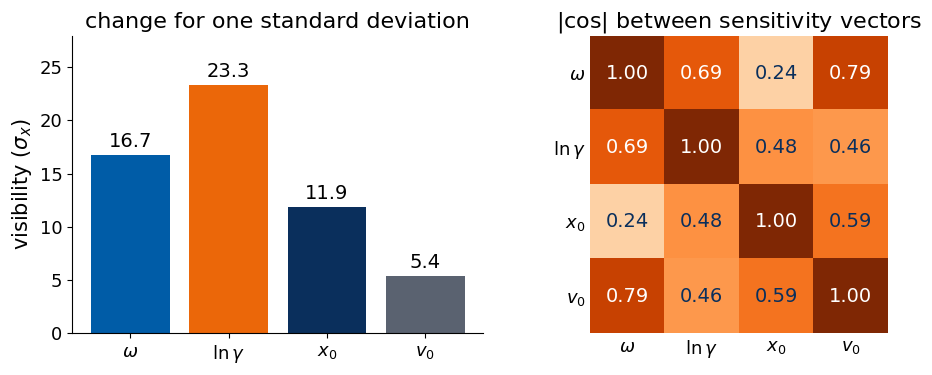

In [21]:
def sensitivity_matrix(mean_fn, P, t):
    """Fisher information F_ab = (1/sigma_x^2) sum_i d<x(t_i)>/dp_a d<x(t_i)>/dp_b at every parameter point P (n, K)."""
    J = vmap(jacfwd(mean_fn), in_dims=(0, None))(torch.as_tensor(P, dtype=torch.float64),
                                                 torch.as_tensor(t, dtype=torch.float64))        # (n, T, K)
    return torch.einsum("nta,ntb->nab", J, J).numpy() / SIGMA_X**2

osc_mean = lambda p, t: mean_trajectory(torch.stack([p[0], torch.exp(p[1]), p[2], p[3]]), t)   # p = (omega, ln gamma, x0, v0)
F_fish = sensitivity_matrix(osc_mean, Pte[:2000], t_grid)
diag = np.sqrt(np.einsum("naa->na", F_fish))
cosines = np.median(np.abs(F_fish / (diag[:, :, None] * diag[:, None, :])), 0)
visibility = np.median(diag, 0) * Pte.std(0)          # change of the trajectory, in units of sigma_x, for a 1-std change
print("median |cos| between the sensitivity vectors d<x>/dp (omega, ln gamma, x0, v0):")
print(np.round(cosines, 2))
print("median visibility  sqrt(F_aa) * std(p_a)  (omega, ln gamma, x0, v0):", np.round(visibility, 1))
nums["fisher_cos"] = np.round(cosines, 3).tolist(); nums["visibility"] = np.round(visibility, 2).tolist()

fig, axs = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw=dict(width_ratios=[1, 1.1]))
axs[0].bar(range(4), visibility, color=[blue, orange, navy, gray])
for i, v in enumerate(visibility):
    axs[0].text(i, v + 0.4, f"{v:.1f}", ha="center", va="bottom", fontsize=14)
axs[0].set_xticks(range(4)); axs[0].set_xticklabels(FACTOR_NAMES); axs[0].set_ylim(0, visibility.max() * 1.2)
axs[0].set_ylabel(r"visibility ($\sigma_x$)"); axs[0].set_title("change for one standard deviation")
axs[1].imshow(cosines, cmap="Oranges", vmin=0, vmax=1)
for (r, c), v in np.ndenumerate(cosines):
    axs[1].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=14, color="white" if v > 0.6 else navy)
axs[1].set_xticks(range(4)); axs[1].set_xticklabels(FACTOR_NAMES); axs[1].set_yticks(range(4)); axs[1].set_yticklabels(FACTOR_NAMES)
axs[1].set_title(r"$|\cos|$ between sensitivity vectors"); axs[1].spines[:].set_visible(False); axs[1].tick_params(length=0)
plt.tight_layout(); save_fig(fig, "traj_sensitivity.png"); plt.show()

The visibilities order the factors. A change of $\ln\gamma$ by one standard deviation moves the trajectory by 23.3 $\sigma_x$, of $\omega$ by 16.7, of $x_0$ by 11.9 and of $v_0$ by only 5.4. The factor that the network drops first at large $\beta$, the initial velocity, is the least visible one, because the KL price of storing it exceeds the gain in reconstruction. The cosines show which directions the data confuse. The largest one, 0.79, belongs to $\omega$ and $v_0$. Within the window a faster oscillation and a negative initial velocity both bring the particle down earlier, and the two changes look alike. The pair $\omega$ and $\ln\gamma$ follows with 0.69, since stronger friction also lowers the damped frequency (8) and shifts the zero crossings. The pair $\omega$ and $x_0$ has the smallest cosine, 0.24. The local, linear picture therefore does not explain why the frequency and the initial position share coordinates. Their mixing is nonlinear, the product structure seen in the frequency coordinate, because the sensitivity to $\omega$ is itself proportional to the amplitude.

The same analysis explains the choice of the parameter ranges. With many oscillation periods in the window, the derivative of the trajectory with respect to $\omega$ grows in time and oscillates. Trajectories for neighbouring frequencies then separate quickly, the map from $\omega$ to the trajectory folds on itself, and a Gaussian code with a smooth decoder cannot follow it. With initial positions of both signs, the trajectories for $(\omega,\gamma,x_0,v_0)$ and for $(\omega,\gamma,-x_0,-v_0)$ differ only by a sign, and the code has to fold again.

The β-VAE thus finds the number of independent factors and, in all models, the damping. It finds the frequency and the initial conditions only as mixtures. The parameter that is most visible and least confusable with the others is the one that ends up in its own coordinate.

## Question-and-answer networks

### SciNet of Iten et al.

[Iten, Metger, Wilming, del Rio and Renner, Phys. Rev. Lett. 124, 010508 (2020)](https://doi.org/10.1103/PhysRevLett.124.010508) proposed a network modelled on how a physicist works. Observations are compressed into a few parameters, and these parameters are used to answer questions about the system. Their network, SciNet, has three parts (their Fig. 1). A feed-forward encoder maps an observation $o$ to a small latent representation. A question $q$, encoded as real numbers, is appended to the latent values, and a feed-forward decoder maps the representation together with the question to an answer $a$. Training uses triples of an observation, a question and the correct answer. Unlike in an autoencoder, the latent representation has to contain only what is needed to answer the questions. To make the latent neurons statistically independent, the authors use the β-VAE cost. The encoder outputs means and standard deviations of independent Gaussians, and with a Gaussian decoder of fixed variance the cost becomes (their Eq. (D1), Supplemental Material)
$$
C_\beta=\lVert\hat a-a\rVert_2^2-\frac\beta2\sum_i\big(\log\sigma_i^2-\mu_i^2-\sigma_i^2\big)+\text{const}=\lVert\hat a-a\rVert_2^2+\beta\,\mathrm{KL}+\text{const}. \tag{43}
$$
The KL term is that of equation (28), and the reconstruction is measured on the answer.

Their first example (Box 1 and Sec. E1 of the Supplemental Material, [arXiv:1807.10300](https://arxiv.org/abs/1807.10300)) is a damped pendulum without noise,
$$
m\ddot x=-\kappa x-b\dot x, \tag{44}
$$
with the mass $m=1\,$kg, the amplitude $A_0=1\,$m and the phase $\delta_0=0$ fixed, so that
$$
x(t)=A_0\,e^{-bt/(2m)}\cos(\omega t+\delta_0),\qquad\omega=\sqrt{\frac\kappa m}\,\sqrt{1-\frac{b^2}{4m\kappa}}. \tag{45}
$$
The spring constant $\kappa$ varies between samples from 5 to 10 kg/s², the damping factor $b$ from 0.5 to 1 kg/s. The observation is the position at 50 equally spaced times between 0 and 5 s, the question is a prediction time between 0 and 10 s, and the answer is the position at that time. The encoder has hidden layers of 500 and 100 neurons and the decoder two layers of 100, all with the exponential linear unit
$$
\mathrm{ELU}(u)=\begin{cases}u,&u>0,\\e^u-1,&u\le0,\end{cases} \tag{46}
$$
a smooth variant of ReLU, and there are three latent neurons (their Table I). Training used 95 000 samples, batch size 512, learning rate $10^{-3}$, $\beta=10^{-3}$ and 1000 epochs (their Table II). The authors report predictions with a root-mean-square error below 2% of the amplitude. They find that the network stores $\kappa$ and $b$ in two latent neurons, the first depending nearly linearly on $b$ and almost not on $\kappa$, the second only on $\kappa$, while the third neuron carries no information (their Fig. 6).

The setting differs from that of our β-VAE in three ways. The decoder answers one question at a time instead of reproducing the whole input, and the questions reach beyond the observed window, so the code must allow extrapolation. The data contain no noise and no nuisance factors, because with fixed amplitude and phase only $\kappa$ and $b$ vary. Finally, $\beta=10^{-3}$ is small in their units. The KL term breaks the rotational symmetry of the latent space but hardly limits the information.

### Pendulum data of Iten et al.

We generate the pendulum data of the paper on the time grid $0,0.1,\dots,10$. The observation is the first 50 points, the times from 0 to 4.9 (the paper uses 50 points between 0 and 5), and the questions are the 101 grid times. The initial condition
$$
x(0)=1,\qquad\dot x(0)=-b/2 \tag{47}
$$
reproduces equation (45) with unit mass and amplitude and zero phase, which the code checks. To see what noise and nuisance factors do, we build two more versions of the same data. The first adds the random force of strength $D=0.002$ (Euler–Maruyama with $\Delta t=0.01$), and the second adds noise and random initial conditions drawn as in equation (23). Each version has 20 000 training and 5000 test trajectories. We also repeat the sensitivity analysis (40) for $(\kappa,b)$ on the observation window.

In [22]:
KAPPA_RANGE, B_RANGE = (5.0, 10.0), (0.5, 1.0)       # spring constant and damping factor of Iten et al. (m = 1)
t_q = 0.1 * np.arange(101)                             # question times 0, 0.1, ..., 10
N_OBS = 50                                             # observation: x at t = 0, 0.1, ..., 4.9

def make_paper_data(n, seed, noise=False, random_ic=False):
    """Trajectories on t_q (n, 101) and factors (kappa, b, x0, v0). Without random_ic: A0 = 1, delta0 = 0,
    i.e. x(0) = 1, x'(0) = -b/2, so that the noise-free solution is exp(-b t / 2) cos(omega t)."""
    rng = np.random.default_rng(seed)
    kap, b = rng.uniform(*KAPPA_RANGE, n), rng.uniform(*B_RANGE, n)
    x0, v0 = (rng.uniform(*X0_RANGE, n), rng.uniform(-V0_MAX, V0_MAX, n)) if random_ic else (np.ones(n), -b / 2)
    if noise:
        X, _ = simulate(np.sqrt(kap), b, x0, v0, rng, n_sub=10, n_rec=101)
    else:
        X = mean_trajectories(np.stack([np.sqrt(kap), b, x0, v0], 1), t_q)
    return X.astype(np.float32), np.stack([kap, b, x0, v0], 1)

# the solution quoted by Iten et al., x(t) = exp(-b t/2) cos(omega t) with omega = sqrt(kappa - b^2/4), is reproduced
Xp, Fp = make_paper_data(5, 0)
om_p = np.sqrt(Fp[:, 0] - Fp[:, 1]**2 / 4)
print("max |x - exp(-bt/2) cos(omega t)| =", np.abs(Xp - np.exp(-Fp[:, 1:2] * t_q / 2) * np.cos(om_p[:, None] * t_q)).max())

SETUPS = {"noise-free, fixed A0 and phase (paper)": dict(noise=False, random_ic=False),
          "with noise": dict(noise=True, random_ic=False),
          "with noise and random x0, v0": dict(noise=True, random_ic=True)}
paper_sets = {name: (make_paper_data(20_000, 21, **kw), make_paper_data(5_000, 22, **kw)) for name, kw in SETUPS.items()}
print({name: (tr[0].shape, te[0].shape) for name, (tr, te) in paper_sets.items()})

# the sensitivity (Fisher) analysis for the parameters (kappa, b) on the observation window
paper_mean = lambda p, t: mean_trajectory(torch.stack([torch.sqrt(p[0]), p[1], torch.ones_like(p[0]), -p[1] / 2]), t)
Fp_fish = sensitivity_matrix(paper_mean, paper_sets["noise-free, fixed A0 and phase (paper)"][1][1][:2000, :2], t_q[:N_OBS])
dp = np.sqrt(np.einsum("naa->na", Fp_fish))
cos_kb = np.median(np.abs(Fp_fish[:, 0, 1]) / (dp[:, 0] * dp[:, 1]))
vis_kb = np.median(dp, 0) * np.array([5, 0.5]) / np.sqrt(12)       # standard deviations of the uniform distributions
print(f"median |cos(kappa, b)| = {cos_kb:.2f}; visibility (kappa, b) = {np.round(vis_kb, 1)}")
nums["paper_cos_kb"] = float(cos_kb); nums["paper_vis_kb"] = vis_kb.round(2).tolist()

max |x - exp(-bt/2) cos(omega t)| = 2.9521143640742764e-08


{'noise-free, fixed A0 and phase (paper)': ((20000, 101), (5000, 101)), 'with noise': ((20000, 101), (5000, 101)), 'with noise and random x0, v0': ((20000, 101), (5000, 101))}


median |cos(kappa, b)| = 0.14; visibility (kappa, b) = [11.2  3. ]


The solution (45) is reproduced to $3\times10^{-8}$, the precision of single-precision arithmetic. On the observation window the median $|\cos|$ between the sensitivity directions of $\kappa$ and $b$ is 0.14, much smaller than the cosines between the factors of our oscillator data. The visibilities are 11.2 and 3.0 $\sigma_x$ for one standard deviation of $\kappa$ and of $b$. In the setting of the paper the two parameters therefore change the trajectory in nearly orthogonal ways.

### Network and cost

Our implementation follows Tables I and II of the paper for the layer sizes, the activation, the batch size, the learning rate and $\beta$. We pair each observation with 8 random question times per training step, so one minibatch contains 4096 triples that share 512 samples of $\mathbf z$. The cost is the mean of the squared answer error over the triples plus $\beta$ times the KL. We train for 100 epochs on 20 000 observations instead of 1000 epochs on 95 000, about 4000 gradient steps instead of about 186 000, and this difference matters when comparing results. In the setting of the paper we therefore also train SciNet for 1000 epochs, about 39 000 steps. With random initial conditions the representation needs two more numbers, so that version gets five latent neurons instead of three. For comparison we also train our β-VAE on each data version ($\beta=4$, $\sigma_x=0.1$, the same latent size, 60 epochs) with the 50 observed points as input. The drawing shows both networks with the widths read from the models. The β-VAE reconstructs the observation, and SciNet receives the question time next to $\mathbf z$ and returns one number.

The two networks differ in what they are asked to do, and the table collects the differences.

| | β-VAE (this notebook) | SciNet (Iten et al.) |
|---|---|---|
| input | the observed trajectory | the observed trajectory and a question time $t$ |
| output | the same trajectory, rebuilt | one number, the position at time $t$ |
| loss | squared reconstruction error divided by $2\sigma_x^2$, plus β times the KL | squared answer error, plus β times the KL |
| content of the latent space | everything needed to rebuild the observation | what is needed to answer the questions |
| prediction beyond the observed window | no | yes, up to 10 s from observations up to 4.9 s |
| activation | ReLU | ELU |

Iten et al. show that the autoencoder is the special case of SciNet with a single question, whose answer is the observation itself. For the pendulum the questions about $x(t)$ on the whole interval from 0 to 10 s need every parameter that shapes the trajectory, so both networks must store the same information and the comparison measures how they arrange it.

The two values of β are on different scales. SciNet weighs the KL against the squared error of one answer with β of $10^{-3}$. Our β-VAE divides the squared error of the whole observation by $2\sigma_x^2$, which is 0.02, before adding β times the KL. Multiplying its loss by 0.02 gives the squared error of the observation plus 0.02β times the KL, which for β of 4 is 0.08 times the KL against the squared errors of all points, or 0.0016 per point for the 50 observed points. Per predicted position the weights of the KL are therefore of the same order in both networks, and the numbers 4 and $10^{-3}$ should not be compared directly.

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
SciNet                                   [1, 50]                   [1, 8]                    --
├─Sequential: 1-1                        [1, 50]                   [1, 100]                  --
│    └─Linear: 2-1                       [1, 50]                   [1, 500]                  25,500
│    └─ELU: 2-2                          [1, 500]                  [1, 500]                  --
│    └─Linear: 2-3                       [1, 500]                  [1, 100]                  50,100
│    └─ELU: 2-4                          [1, 100]                  [1, 100]                  --
├─Linear: 1-2                            [1, 100]                  [1, 3]                    303
├─Linear: 1-3                            [1, 100]                  [1, 3]                    303
├─Sequential: 1-4                        [1, 8, 4]                 [1, 8, 1]                 --
│    └─Linear: 2-5       

$\beta$-VAE: widths {'enc': [50, 256, 128], 'd': 3, 'extra': 0, 'dec': [128, 256, 50]}, parameters from the drawing = torchinfo total = 93,112


SciNet: widths {'enc': [50, 500, 100], 'd': 3, 'extra': 1, 'dec': [100, 100, 1]}, parameters from the drawing = torchinfo total = 86,907


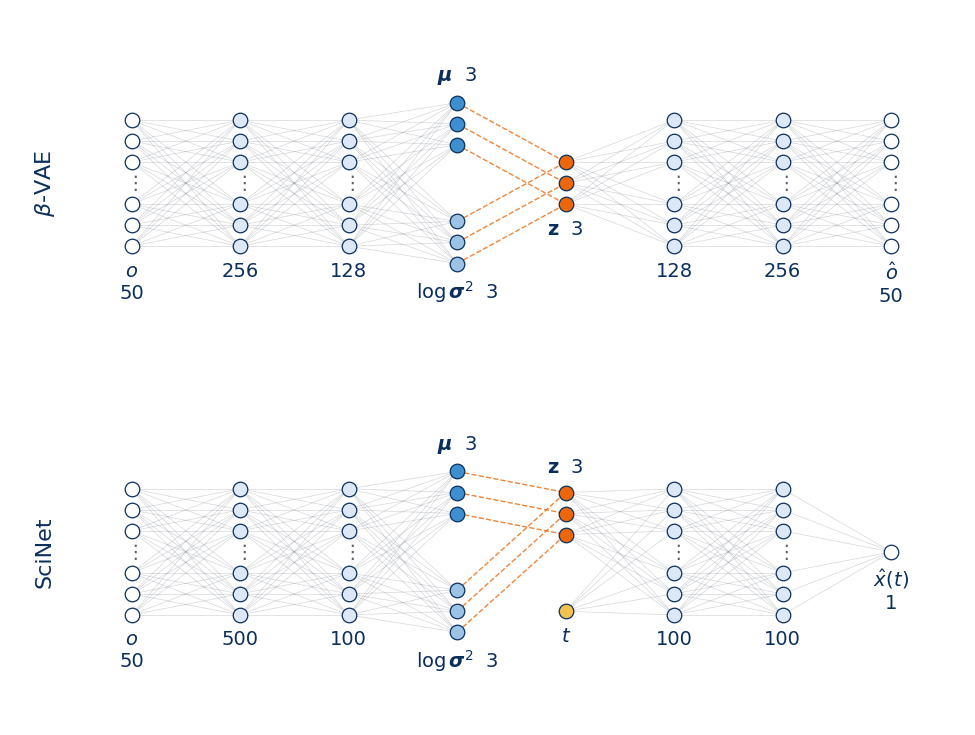

In [23]:
class SciNet(nn.Module):
    """Question-and-answer network in the style of Iten et al., with ELU activations.
    encoder: observation o (B, 50) -> 500 -> 100 -> mu (B, d), logvar (B, d)
    decoder: [z, t] (B, Q, d + 1)  -> 100 -> 100 -> answer x(t) (B, Q)"""
    def __init__(self, n_obs=N_OBS, d=3):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_obs, 500), nn.ELU(), nn.Linear(500, 100), nn.ELU())
        self.mu, self.logvar = nn.Linear(100, d), nn.Linear(100, d)
        self.dec = nn.Sequential(nn.Linear(d + 1, 100), nn.ELU(), nn.Linear(100, 100), nn.ELU(), nn.Linear(100, 1))
    def encode(self, o):
        h = self.enc(o)
        return self.mu(h), self.logvar(h)
    def answer(self, z, q):
        """z (B, d), question times q (B, Q) -> predicted positions (B, Q)."""
        zq = torch.cat([z[:, None, :].expand(-1, q.shape[1], -1), q[..., None]], -1)
        return self.dec(zq)[..., 0]
    def forward(self, o, q):
        mu, logvar = self.encode(o)
        return self.answer(reparametrise(mu, logvar), q), mu, logvar

T_Q = torch.tensor(t_q, dtype=torch.float32)
def scinet_loss(model, batch, beta=1e-3, n_q=8):
    """Cost of Iten et al. per (observation, question, answer) triple: (x_hat - x)^2 + beta KL;
    n_q random questions per observation share one sample z."""
    o, a = batch                                   # observation (B, 50), answers on all question times (B, 101)
    mu, logvar = model.encode(o)
    idx = torch.randint(0, a.shape[1], (o.shape[0], n_q))
    pred = model.answer(reparametrise(mu, logvar), T_Q[idx])
    rec = ((pred - torch.gather(a, 1, idx)) ** 2).mean()
    kl = kl_per_dim(mu, logvar).sum(1).mean()
    return rec + beta * kl, {"loss": rec + beta * kl, "rec": rec, "kl": kl}

torch.manual_seed(0)
sn_demo, bv_demo = SciNet(d=3), TrajVAE(N_OBS, 3)
stats_sn = summary(sn_demo, input_data=[torch.zeros(1, N_OBS), torch.zeros(1, 8)], col_names=["input_size", "output_size", "num_params"],
                   depth=2, verbose=0)
stats_bv = summary(bv_demo, input_size=(1, N_OBS), verbose=0)
print(stats_sn)
print(f"beta-VAE with 50 inputs and d = 3: {stats_bv.total_params:,} parameters")

fig, axs = plt.subplots(2, 1, figsize=(10, 7.6))
for a, model, lab, args in [(axs[0], bv_demo, r"$\beta$-VAE", (r"$o$", r"$\hat o$")),
                            (axs[1], sn_demo, "SciNet", (r"$o$", r"$\hat x(t)$", "$t$"))]:
    wd_ = draw_network(a, model, *args)
    a.text(-1.0, 0, lab, rotation=90, ha="center", va="center", fontsize=16, color=navy)
    a.set_xlim(-1.4, 9.6); a.set_ylim(-2.8, 2.8)
    st = stats_bv if model is bv_demo else stats_sn
    assert params_from_widths(wd_) == st.total_params == sum(p.numel() for p in model.parameters())
    print(f"{lab}: widths {wd_}, parameters from the drawing = torchinfo total = {st.total_params:,}")
plt.tight_layout(); save_fig(fig, "traj_scinet.png"); plt.show()
nums["scinet_params"] = int(stats_sn.total_params); nums["paper_bvae_params"] = int(stats_bv.total_params)

### Training and probing

We probe both networks as before, with the KL per latent neuron, the active neurons, and $|\rho|$ with $\kappa$ and $b$ on the test set. For each parameter we print the best and the second-best $|\rho|$ over the active neurons. A large best value with a small second value means that one neuron, and only one, follows the parameter. The prediction error of SciNet is the root-mean-square error over all 101 question times of every test trajectory.

In [24]:
EPOCHS_QA = 100
probe = {}
t0 = time.time()
for j, (name, ((Xa, Fa), (Xb, Fb))) in enumerate(paper_sets.items()):
    d_lat = 5 if SETUPS[name]["random_ic"] else 3
    Xa_t = torch.as_tensor(Xa)
    sn, _ = train(lambda: SciNet(d=d_lat), scinet_loss, (Xa_t[:, :N_OBS], Xa_t), EPOCHS_QA, 0,
                  name=f"traj_scinet_setup{j}", batch_size=512, log_every=50)
    bv, _ = train(lambda: TrajVAE(N_OBS, d_lat), partial(beta_vae_loss, beta=4), (Xa_t[:, :N_OBS].contiguous(),), 60, 0,
                  name=f"traj_paper_bvae_setup{j}", log_every=30)
    P_b = Fb if SETUPS[name]["random_ic"] else Fb[:, :2]
    nets = [("SciNet", sn), ("beta-VAE", bv)]
    if j == 0:                                     # the setting of the paper, also trained for 1000 epochs as there
        sn_long, _ = train(lambda: SciNet(d=d_lat), scinet_loss, (Xa_t[:, :N_OBS], Xa_t), 1000, 0,
                           name="traj_scinet_setup0_1000ep", batch_size=512, log_every=250)
        nets.append(("SciNet, 1000 epochs", sn_long))
    for net_name, net in nets:
        with torch.no_grad():
            mu, lv = (a.numpy() for a in net.encode(torch.as_tensor(Xb[:, :N_OBS])))
        kl_n = kl_per_dim(mu, lv).mean(0)
        probe[name, net_name] = dict(kl=kl_n, active=np.flatnonzero(kl_n > ACTIVE_NATS), corr=abs_corr(mu, P_b), mu=mu)
        if net_name.startswith("SciNet"):
            with torch.no_grad():
                pred = net.answer(torch.as_tensor(mu), T_Q.repeat(len(Xb), 1)).numpy()
            probe[name, net_name]["rmse"] = float(np.sqrt(((pred - Xb) ** 2).mean()))
            probe[name, net_name]["pred"] = pred
print(f"question-and-answer networks and beta-VAEs ready in {time.time() - t0:.0f} s")

print("setup | network | KL per latent neuron | |rho| with kappa (best, second) | |rho| with b (best, second)")
rows_qa = {}
for (name, net_name), p in probe.items():
    c = p["corr"][p["active"]] if len(p["active"]) else np.zeros((1, p["corr"].shape[1]))
    srt = np.sort(c, 0)[::-1]
    second = srt[1] if len(srt) > 1 else np.zeros(c.shape[1])
    rows_qa[name, net_name] = dict(best=srt[0].tolist(), second=second.tolist(), n_active=int(len(p["active"])))
    print(f"{name:38s} | {net_name:19s} | {np.round(np.sort(p['kl'])[::-1], 2)} | {srt[0, 0]:.2f}, {second[0]:.2f} | {srt[0, 1]:.2f}, {second[1]:.2f}")
print("rms prediction error of SciNet over t in [0, 10]:", {f"{n} | {net}": round(p["rmse"], 4) for (n, net), p in probe.items() if "rmse" in p})
name_ic = list(SETUPS)[2]
for net_name in ("SciNet", "beta-VAE"):
    p = probe[name_ic, net_name]
    print(f"{name_ic}, {net_name}: |rho| of the active neurons with (kappa, b, x0, v0):")
    print(np.round(p["corr"][p["active"]], 2))
nums["qa"] = {f"{i}_{net}": rows_qa[n, net] for i, n in enumerate(SETUPS) for net in ("SciNet", "beta-VAE")}
nums["qa_long"] = rows_qa[list(SETUPS)[0], "SciNet, 1000 epochs"]
nums["qa_rmse"] = [probe[n, "SciNet"]["rmse"] for n in SETUPS]
nums["qa_rmse_long"] = probe[list(SETUPS)[0], "SciNet, 1000 epochs"]["rmse"]

  traj_scinet_setup0 epoch   50: loss 0.007  rec 0.005  kl 1.698   (232.9 s)


  traj_scinet_setup0 epoch  100: loss 0.005  rec 0.003  kl 1.839   (481.3 s)


  traj_paper_bvae_setup0 epoch   30: loss 12.247  rec 4.082  kl 2.041   (345.5 s)


  traj_paper_bvae_setup0 epoch   60: loss 12.159  rec 3.982  kl 2.044   (1024.6 s)


  traj_scinet_setup0_1000ep epoch  250: loss 0.004  rec 0.002  kl 1.989   (374.8 s)


...

  traj_scinet_setup2 epoch   50: loss 0.014  rec 0.010  kl 4.054   ( 12.0 s)


  traj_scinet_setup2 epoch  100: loss 0.010  rec 0.006  kl 3.698   ( 24.1 s)


  traj_paper_bvae_setup2 epoch   30: loss 21.527  rec 8.542  kl 3.246   ( 16.4 s)


  traj_paper_bvae_setup2 epoch   60: loss 21.363  rec 8.446  kl 3.229   ( 33.2 s)


question-and-answer networks and beta-VAEs ready in 3299 s
setup | network | KL per latent neuron | |rho| with kappa (best, second) | |rho| with b (best, second)
noise-free, fixed A0 and phase (paper) | SciNet              | [1.6  0.24 0.  ] | 1.00, 0.19 | 0.97, 0.02
noise-free, fixed A0 and phase (paper) | beta-VAE            | [1.65 0.4  0.  ] | 0.99, 0.01 | 0.97, 0.08
noise-free, fixed A0 and phase (paper) | SciNet, 1000 epochs | [1.65 0.46 0.  ] | 0.99, 0.06 | 0.98, 0.08
with noise                             | SciNet              | [1.74 0.48 0.  ] | 0.99, 0.44 | 0.88, 0.02
with noise                             | beta-VAE            | [1.74 0.51 0.  ] | 0.98, 0.01 | 0.95, 0.08
with noise and random x0, v0           | SciNet              | [2.28 1.41 0.03 0.03 0.01] | 0.93, 0.38 | 0.31, 0.01
with noise and random x0, v0           | beta-VAE            | [1.87 1.32 0.   0.   0.  ] | 0.90, 0.04 | 0.27, 0.11
rms prediction error of SciNet over t in [0, 10]: {'noise-free, fixed A0 and

In the setting of the paper SciNet already separates the two parameters after 100 epochs. Two latent neurons are active (1.60 and 0.24 nats) and the third one carries no information (0.00 nats). One neuron follows $\kappa$ with $|\rho|$ of 1.00 and the other $b$ with 0.97, and the second-best correlations are 0.19 and 0.02. The prediction error over the times from 0 to 10 is 0.0514, about 5% of the amplitude. After 1000 epochs, as in the paper, the correlations are 0.99 for $\kappa$ and 0.98 for $b$, the second-best values are 0.06 and 0.08, the third neuron again carries 0.00 nats, and the prediction error drops to 0.0178, 1.8% of the amplitude. This reproduces the finding of Iten et al. of one neuron per parameter and a prediction error below 2%.

The β-VAE with $\beta=4$ reaches the same separation after 60 epochs, with $|\rho|$ of 0.99 for $\kappa$ and 0.97 for $b$ and second-best values of 0.01 and 0.08. Its KL term is far more expensive. Per observed position SciNet weighs a squared error of one with 1 and the KL with $10^{-3}$, while our β-VAE weighs the squared error with 50 and the KL with 4, so the relative weights of the KL term are
$$
\frac{\beta_{\rm SciNet}}{1}=10^{-3},\qquad\frac{\beta}{1/(2\sigma_x^2)}=\frac{4}{50}=0.08, \tag{48}
$$
eighty times larger for the β-VAE.

The random force of strength $D=0.002$ changes little for the β-VAE, which separates $\kappa$ (0.98, second 0.01) and $b$ (0.95, second 0.08). SciNet still has one neuron for each parameter (0.99 for $\kappa$ and 0.88 for $b$), but its second neuron also correlates with $\kappa$ at 0.44, and its prediction error grows to 0.0609. Random initial conditions change more. SciNet keeps two of its five neurons active (2.28 and 1.41 nats), the first following $\kappa$ (0.93) and the second $x_0$ (0.87). The damping reaches only 0.31 and the initial velocity 0.21, and the prediction error is 0.0725. For answering questions over the times from 0 to 10, the frequency and the starting point matter most, and within 100 epochs the network has found no room for the damping. The β-VAE also keeps two active coordinates (1.87 and 1.32 nats), for $\kappa$ (0.90) and $x_0$ (0.75), and $b$ reaches only 0.27. With nuisance factors both networks store the most visible parameters first, as in our oscillator data.

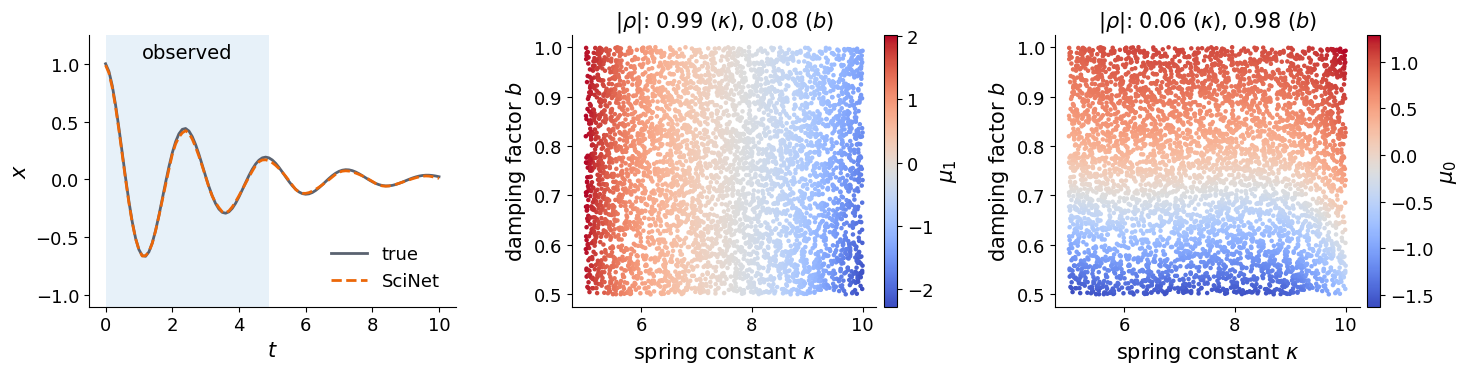

test trajectory shown: kappa = 6.83, b = 0.68


In [25]:
name0 = list(SETUPS)[0]
(_, _), (Xb0, Fb0) = paper_sets[name0]
p0 = probe[name0, "SciNet, 1000 epochs"]
act0 = p0["active"][np.argsort(p0["kl"][p0["active"]])[::-1]]
fig, axs = plt.subplots(1, 1 + len(act0), figsize=(5 * (1 + len(act0)), 4))
i0 = 0
axs[0].plot(t_q, Xb0[i0], color=gray, label="true"); axs[0].plot(t_q, p0["pred"][i0], "--", color=orange, label="SciNet")
axs[0].axvspan(0, t_q[N_OBS - 1], color=sky, alpha=0.12, lw=0); axs[0].text(2.45, 1.05, "observed", ha="center", fontsize=14)
axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$x$"); axs[0].legend(loc="lower right"); axs[0].set_ylim(-1.1, 1.25)
for a, kz in zip(axs[1:], act0):
    sc = a.scatter(Fb0[:, 0], Fb0[:, 1], c=p0["mu"][:, kz], cmap="coolwarm", s=5, rasterized=True)
    fig.colorbar(sc, ax=a, pad=0.02).set_label(rf"$\mu_{kz}$")
    a.set_xlabel(r"spring constant $\kappa$"); a.set_ylabel("damping factor $b$")
    a.set_title(rf"$|\rho|$: {p0['corr'][kz, 0]:.2f} ($\kappa$), {p0['corr'][kz, 1]:.2f} ($b$)", fontsize=15)
plt.tight_layout(); save_fig(fig, "traj_scinet_latent.png"); plt.show()
print("test trajectory shown: kappa = %.2f, b = %.2f" % tuple(Fb0[i0, :2]))

The figure shows SciNet after 1000 epochs in the setting of the paper. On the left it predicts a test trajectory ($\kappa$ of 6.83, $b$ of 0.68) over the times from 0 to 10 from the observed first half (shaded). In the middle and on the right every test observation is placed at its true $(\kappa,b)$ and coloured by the mean of one latent neuron. The colour of the first neuron changes only along $\kappa$ and that of the second only along $b$, the analogue of Fig. 6 of the paper. When the data contain only these two parameters, the question-and-answer network and the β-VAE find the same physical parameters.

## Two coupled oscillators

### Normal modes

Two equal masses $m$ are each attached to a wall by a spring $k$ and to each other by a coupling spring $k_c$. Both move in the same fluid with friction rate $\gamma$, and each is hit by its own random force,
$$
\begin{aligned}
m\ddot x_1&=-kx_1-k_c(x_1-x_2)-m\gamma\dot x_1+m\sqrt{2D}\,\xi_1(t),\\
m\ddot x_2&=-kx_2-k_c(x_2-x_1)-m\gamma\dot x_2+m\sqrt{2D}\,\xi_2(t),
\end{aligned} \tag{49}
$$
with independent white noises $\xi_1$ and $\xi_2$. In matrix form the restoring forces are given by the stiffness matrix
$$
K=\begin{pmatrix}k+k_c&-k_c\\-k_c&k+k_c\end{pmatrix}. \tag{50}
$$
Its eigenvectors are the normal modes. In the in-phase motion along $(1,1)$ the coupling spring is never stretched, and in the anti-phase motion along $(1,-1)$ it is stretched twice as much as each mass moves. The two mode frequencies are
$$
\omega_1=\sqrt{k/m},\qquad\omega_2=\sqrt{(k+2k_c)/m}. \tag{51}
$$
We find them with SymPy and confirm them with `numpy.linalg.eigvalsh` for random spring constants.

In [26]:
k, kc, m_ = sp.symbols("k k_c m", positive=True)
K = sp.Matrix([[k + kc, -kc], [-kc, k + kc]])            # m x'' = -K x - m gamma x' + noise
for val, mult, vecs in K.eigenvects():
    print(f"eigenvalue {sp.simplify(val)}:  omega^2 = {sp.simplify(val / m_)},  mode {list(vecs[0])}")

# numerical check for a few random spring constants (m = 1)
rng = np.random.default_rng(0)
for _ in range(3):
    kv, kcv = rng.uniform(1, 4), rng.uniform(0.2, 2)
    ev_num = np.linalg.eigvalsh(np.array([[kv + kcv, -kcv], [-kcv, kv + kcv]]))
    print(f"k = {kv:.3f}, k_c = {kcv:.3f}: eigvalsh -> omega = {np.sqrt(ev_num).round(6)},"
          f"  formulas -> {np.round([np.sqrt(kv), np.sqrt(kv + 2 * kcv)], 6)}")

eigenvalue k:  omega^2 = k/m,  mode [1, 1]
eigenvalue k + 2*k_c:  omega^2 = (k + 2*k_c)/m,  mode [-1, 1]
k = 2.911, k_c = 0.686: eigvalsh -> omega = [1.706132 2.069328],  formulas -> [1.706132 2.069328]
k = 1.123, k_c = 0.230: eigvalsh -> omega = [1.059679 1.257943],  formulas -> [1.059679 1.257943]
k = 3.440, k_c = 1.843: eigvalsh -> omega = [1.854673 2.669406],  formulas -> [1.854673 2.669406]


In the mode coordinates
$$
q_\pm=\frac{x_1\pm x_2}{\sqrt2} \tag{52}
$$
the two equations separate,
$$
\ddot q_+=-\omega_1^2q_+-\gamma\dot q_++\sqrt{2D}\,\xi_+,\qquad\ddot q_-=-\omega_2^2q_--\gamma\dot q_-+\sqrt{2D}\,\xi_-,\qquad\xi_\pm=\frac{\xi_1\pm\xi_2}{\sqrt2}. \tag{53}
$$
The friction is the same for both masses, so it does not couple the modes, and $\xi_\pm$ are again independent white noises of unit strength, because
$$
\langle\xi_+\xi_-\rangle=\tfrac12\big(\langle\xi_1^2\rangle-\langle\xi_2^2\rangle\big)=0. \tag{54}
$$
The two masses are therefore two independent noisy oscillators of the kind of equation (1), seen through a rotation of $45^\circ$, and a trajectory depends on the springs only through $\omega_1$ and $\omega_2$. We run the Euler–Maruyama integrator of the two masses without noise from $x_1=1$ and $x_2=0.2$ at rest, and compare $q_\pm$ with the exact damped oscillators at $\omega_1$ and $\omega_2$ (unit mass).

In [27]:
def simulate_two(k, kc, gamma, x10, x20, v10, v20, rng, D=D_NOISE, dt=DT, n_sub=N_SUB, n_rec=T_POINTS):
    """Euler-Maruyama for N pairs of coupled masses (m = 1); all parameters (N,). Returns positions (N, 2, n_rec)."""
    x1, x2, v1, v2 = (np.array(a, float) for a in (x10, x20, v10, v20))
    X = np.empty((len(x1), 2, n_rec)); X[:, 0, 0], X[:, 1, 0] = x1, x2
    kick = np.sqrt(2 * D * dt)
    for i in range(1, n_rec):
        for _ in range(n_sub):
            a1 = -k * x1 - kc * (x1 - x2) - gamma * v1
            a2 = -k * x2 - kc * (x2 - x1) - gamma * v2
            e1, e2 = rng.standard_normal((2, len(x1)))               # independent noises on the two masses
            x1, x2, v1, v2 = x1 + v1 * dt, x2 + v2 * dt, v1 + a1 * dt + kick * e1, v2 + a2 * dt + kick * e2
        X[:, 0, i], X[:, 1, i] = x1, x2
    return X

# check without noise: the mode coordinates q_+ = (x1 + x2)/sqrt2 and q_- = (x1 - x2)/sqrt2 are single damped oscillators
kv, kcv, gv = 2.0, 1.0, 0.3
one = np.ones(1)
X2 = simulate_two(kv * one, kcv * one, gv * one, 1.0 * one, 0.2 * one, 0 * one, 0 * one, np.random.default_rng(0), D=0.0,
                  n_sub=1, n_rec=601)[0]
t_fine = DT * np.arange(601)
q_plus, q_minus = (X2[0] + X2[1]) / np.sqrt(2), (X2[0] - X2[1]) / np.sqrt(2)
for name, q, om in [("q+", q_plus, np.sqrt(kv)), ("q-", q_minus, np.sqrt(kv + 2 * kcv))]:
    ex = mean_trajectories([[om, gv, q[0], 0.0]], t_fine)[0]          # both masses start at rest
    print(f"{name}: max |Euler (dt = {DT}) - damped oscillator with omega = {om:.4f}| = {np.abs(q - ex).max():.4f}")

q+: max |Euler (dt = 0.01) - damped oscillator with omega = 1.4142| = 0.0199
q-: max |Euler (dt = 0.01) - damped oscillator with omega = 2.0000| = 0.0276


The largest differences, 0.0199 for the in-phase and 0.0276 for the anti-phase mode, are of order $\Delta t$, as expected for the Euler method. The figure shows the system, the two modes, and one noisy trajectory started from $x_1=1$ and $x_2=0$ at rest. Both modes are excited, and the motion is transferred back and forth between the masses at the beat frequency $\omega_2-\omega_1$.

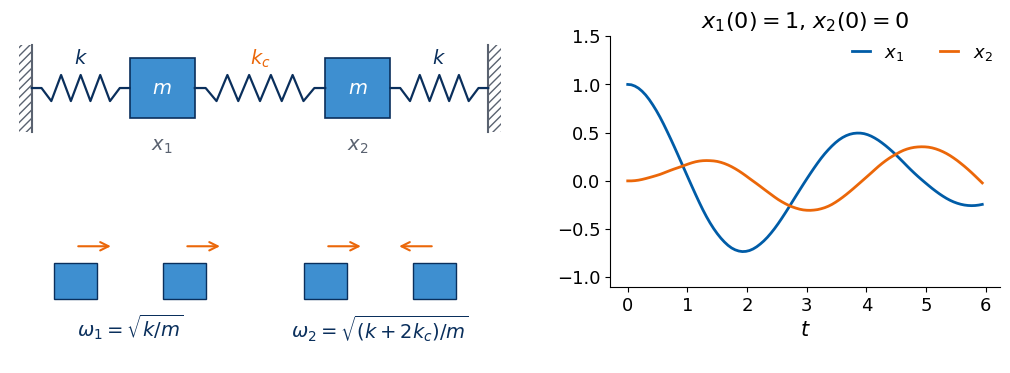

In [28]:
def draw_two_masses(ax, y=0.0):
    """Wall - k - m - k_c - m - k - wall."""
    draw_wall(ax, 0.0, y - 0.4, y + 0.4); draw_wall(ax, 4.2, y - 0.4, y + 0.4, side="right")
    draw_spring(ax, 0.0, 0.9, y, n_coils=4); draw_spring(ax, 1.5, 2.7, y, n_coils=5); draw_spring(ax, 3.3, 4.2, y, n_coils=4)
    for xm, lab in [(0.9, "1"), (2.7, "2")]:
        ax.add_patch(Rectangle((xm, y - 0.28), 0.6, 0.56, facecolor=sky, edgecolor=navy, lw=1.2))
        ax.text(xm + 0.3, y, "$m$", ha="center", va="center", fontsize=14, color="white")
        ax.text(xm + 0.3, y - 0.45, f"$x_{lab}$", ha="center", va="top", fontsize=14, color=gray)
    ax.text(0.45, y + 0.22, "$k$", ha="center", fontsize=14, color=navy)
    ax.text(2.1, y + 0.22, "$k_c$", ha="center", fontsize=14, color=orange)
    ax.text(3.75, y + 0.22, "$k$", ha="center", fontsize=14, color=navy)

fig = plt.figure(figsize=(10, 3.8))
a0 = fig.add_axes([0.0, 0.42, 0.5, 0.55]); draw_two_masses(a0); a0.set_xlim(-0.2, 4.4); a0.set_ylim(-0.75, 0.55)
a0.set_aspect("equal"); a0.axis("off")
for j, (title, sgn, om_lab) in enumerate([("in phase", 1, r"$\omega_1=\sqrt{k/m}$"), ("anti-phase", -1, r"$\omega_2=\sqrt{(k+2k_c)/m}$")]):
    a = fig.add_axes([0.0 + 0.25 * j, 0.0, 0.24, 0.36])
    for xm, s in [(0.6, 1), (1.6, sgn)]:
        a.add_patch(Rectangle((xm, -0.2), 0.4, 0.4, facecolor=sky, edgecolor=navy, lw=1))
        a.annotate("", xy=(xm + 0.2 + 0.35 * s, 0.38), xytext=(xm + 0.2, 0.38), arrowprops=dict(arrowstyle="->", color=orange, lw=1.5))
    a.text(1.3, -0.35, om_lab, ha="center", va="top", fontsize=14, color=navy)
    a.set_xlim(0.2, 2.4); a.set_ylim(-0.9, 0.6); a.axis("off")
a1 = fig.add_axes([0.6, 0.2, 0.39, 0.66])
X_demo = simulate_two(*(np.array([v]) for v in (2.0, 0.6, 0.25, 1.0, 0.0, 0.0, 0.0)), np.random.default_rng(3))[0]
a1.plot(t_grid, X_demo[0], color=blue, label="$x_1$"); a1.plot(t_grid, X_demo[1], color=orange, label="$x_2$")
a1.set_xlabel("$t$"); a1.legend(loc="upper right", ncol=2, handlelength=1.0, borderaxespad=0.0)
a1.set_ylim(-1.1, 1.5); a1.set_title(r"$x_1(0)=1$, $x_2(0)=0$")
save_fig(fig, "traj_coupled.png"); plt.show()

### Coupled-mass data

One sample is the two-channel trajectory of both masses at the 100 times of equation (22), flattened into
$$
\mathbf x_i=\big(x_{1}(t_0),\dots,x_{1}(t_{99}),\,x_{2}(t_0),\dots,x_{2}(t_{99})\big)\in\mathbb R^{200}. \tag{55}
$$
We draw the spring constants, the friction and the initial conditions independently for every sample,
$$
k\sim\mathcal U[1,4],\quad k_c\sim\mathcal U[0.2,2],\quad\ln\gamma\sim\mathcal U[\ln0.2,\ln2],\quad x_1(0)\sim\mathcal U[0.5,1.5],\quad x_2(0)\sim\mathcal U[-1,1],\quad\dot x_{1,2}(0)\sim\mathcal U[-0.5,0.5], \tag{56}
$$
with unit mass. The noise strength, the time step and the recorded times are those of the single oscillator. There are 20 000 training and 5000 test samples with seven factors each. Because $k$ and $k_c$ are drawn independently, the mode frequencies (51) are correlated with each other, and $\omega_2$ is correlated with both springs. This makes the question decidable. A coordinate that follows $\omega_2$ has $|\rho|$ close to 1 with $\omega_2$ and clearly smaller with $k_c$, and a coordinate that follows $k_c$ behaves the other way round.

In [29]:
K_RANGE, KC_RANGE, GAMMA2_RANGE = (1.0, 4.0), (0.2, 2.0), (0.2, 2.0)
def make_two_data(n, seed):
    """n trajectories of two coupled masses, (n, 2, 100), and factors (n, 7) = (k, k_c, gamma, x1, x2, v1, v2) at t = 0."""
    rng = np.random.default_rng(seed)
    kk, kc_, ga = rng.uniform(*K_RANGE, n), rng.uniform(*KC_RANGE, n), np.exp(rng.uniform(*np.log(GAMMA2_RANGE), n))
    x1, x2 = rng.uniform(*X0_RANGE, n), rng.uniform(-1.0, 1.0, n)
    v1, v2 = rng.uniform(-V0_MAX, V0_MAX, n), rng.uniform(-V0_MAX, V0_MAX, n)
    X = simulate_two(kk, kc_, ga, x1, x2, v1, v2, rng)
    return X.astype(np.float32), np.stack([kk, kc_, ga, x1, x2, v1, v2], 1)

X2tr, F2tr = make_two_data(20_000, seed=11)
X2te, F2te = make_two_data(5_000, seed=12)
w1_te, w2_te = np.sqrt(F2te[:, 0]), np.sqrt(F2te[:, 0] + 2 * F2te[:, 1])
P2_springs = np.stack([F2te[:, 0], F2te[:, 1], np.log(F2te[:, 2])], 1)
P2_modes = np.stack([w1_te, w2_te, np.log(F2te[:, 2])], 1)
P2_ic = F2te[:, 3:]
print(f"training / test samples: {X2tr.shape} / {X2te.shape};  omega_1 in [{w1_te.min():.2f}, {w1_te.max():.2f}],"
      f" omega_2 in [{w2_te.min():.2f}, {w2_te.max():.2f}] (test set)")
print("correlations in the test data:  rho(omega_2, k) = %.2f,  rho(omega_2, k_c) = %.2f,  rho(omega_1, omega_2) = %.2f"
      % (np.corrcoef(w2_te, F2te[:, 0])[0, 1], np.corrcoef(w2_te, F2te[:, 1])[0, 1], np.corrcoef(w1_te, w2_te)[0, 1]))
nums["two_data_corr"] = {"w2_k": float(np.corrcoef(w2_te, F2te[:, 0])[0, 1]), "w2_kc": float(np.corrcoef(w2_te, F2te[:, 1])[0, 1]),
                         "w1_w2": float(np.corrcoef(w1_te, w2_te)[0, 1])}

training / test samples: (20000, 2, 100) / (5000, 2, 100);  omega_1 in [1.00, 2.00], omega_2 in [1.20, 2.82] (test set)
correlations in the test data:  rho(omega_2, k) = 0.63,  rho(omega_2, k_c) = 0.75,  rho(omega_1, omega_2) = 0.63


In the test set $\omega_1$ lies between 1.00 and 2.00 and $\omega_2$ between 1.20 and 2.82. The correlation of $\omega_2$ with $k$ is 0.63, with $k_c$ 0.75, and that of the two mode frequencies 0.63. A coordinate that follows $\omega_2$ perfectly would therefore have $|\rho|$ of 0.75 with $k_c$, and a coordinate that follows $k_c$ perfectly would have $|\rho|$ of 0.75 with $\omega_2$.

### Springs or normal modes

We train the same β-VAE with 200 inputs and $d=10$ latent coordinates for $\beta=4$ and two seeds. Its active coordinates are correlated with two descriptions of the same oscillators, the spring constants $(k,k_c,\ln\gamma)$ and the normal-mode frequencies $(\omega_1,\omega_2,\ln\gamma)$. For every model we print the largest $|\rho|$ of each parameter over the active coordinates.

In [30]:
D2_LATENT, BETAS2, SEEDS2 = 10, [4], [0, 1]
t0 = time.time()
vaes2, ev2 = {}, {}
X2tr_flat, X2te_flat = X2tr.reshape(len(X2tr), -1), X2te.reshape(len(X2te), -1)     # (n, 200): x1(t) then x2(t)
X2tr_t = torch.as_tensor(X2tr_flat)
for beta in BETAS2:
    for s in SEEDS2:
        vaes2[beta, s], _ = train(lambda: TrajVAE(2 * T_POINTS, D2_LATENT), partial(beta_vae_loss, beta=beta), (X2tr_t,), EPOCHS, s,
                                  name=f"traj_two_beta{beta}_seed{s}")
        ev2[beta, s] = evaluate(vaes2[beta, s], X2te_flat)
print(f"{len(vaes2)} models ready in {time.time() - t0:.0f} s")
print(f"parameters of the two-mass beta-VAE: {sum(p.numel() for p in vaes2[BETAS2[0], 0].parameters()):,}")
summary2 = {}
for key in vaes2:
    mu, lv = ev2[key][0], ev2[key][1]
    kl2 = kl_per_dim(mu, lv).mean(0); act2 = np.flatnonzero(kl2 > ACTIVE_NATS)
    act2 = act2[np.argsort(kl2[act2])[::-1]]
    c_spr, c_mod, c_ic = abs_corr(mu, P2_springs)[act2], abs_corr(mu, P2_modes)[act2], abs_corr(mu, P2_ic)[act2]
    summary2[key] = dict(active=act2, kl=kl2, c_spr=c_spr, c_mod=c_mod, c_ic=c_ic)
    print(f"beta {key[0]}, seed {key[1]}: rate {ev2[key][2]:.2f}, distortion {ev2[key][3]:.2f}, active {len(act2)};"
          f"  best |rho| with k, k_c, ln gamma: {np.round(c_spr.max(0), 2)};  with omega_1, omega_2, ln gamma: {np.round(c_mod.max(0), 2)}")
nums["two"] = {f"{b}_{s}": {"n_active": int(len(v["active"])), "best_springs": v["c_spr"].max(0).round(3).tolist(),
                            "best_modes": v["c_mod"].max(0).round(3).tolist()} for (b, s), v in summary2.items()}

  traj_two_beta4_seed0 epoch   20: loss 64.405  rec 22.435  kl 10.493   ( 11.2 s)


  traj_two_beta4_seed0 epoch   40: loss 62.893  rec 21.291  kl 10.401   ( 22.4 s)


  traj_two_beta4_seed0 epoch   60: loss 62.375  rec 20.903  kl 10.368   ( 35.0 s)


  traj_two_beta4_seed0 epoch   80: loss 62.224  rec 20.725  kl 10.375   ( 47.4 s)


  traj_two_beta4_seed1 epoch   20: loss 65.520  rec 22.885  kl 10.659   ( 13.2 s)


  traj_two_beta4_seed1 epoch   40: loss 63.125  rec 21.455  kl 10.418   ( 29.3 s)


  traj_two_beta4_seed1 epoch   60: loss 62.405  rec 21.020  kl 10.346   ( 49.5 s)


  traj_two_beta4_seed1 epoch   80: loss 61.784  rec 20.492  kl 10.323   (145.8 s)
2 models ready in 193 s
parameters of the two-mass beta-VAE: 172,764
beta 4, seed 0: rate 10.22, distortion 21.72, active 6;  best |rho| with k, k_c, ln gamma: [0.61 0.52 0.54];  with omega_1, omega_2, ln gamma: [0.61 0.8  0.54]


beta 4, seed 1: rate 10.18, distortion 21.53, active 6;  best |rho| with k, k_c, ln gamma: [0.52 0.59 0.44];  with omega_1, omega_2, ln gamma: [0.51 0.79 0.44]


Both seeds use six active coordinates for the seven factors, with a rate of 10.22 and 10.18 nats and a distortion of 21.72 and 21.53 nats. The network has 172 764 parameters. In both seeds the largest correlation with $\omega_2$ (0.80 and 0.79) is clearly larger than that with $k_c$ (0.52 and 0.59). The in-phase frequency and the spring $k$ reach only 0.61 in seed 0 and 0.51 to 0.52 in seed 1, and $\ln\gamma$ reaches 0.54 and 0.44.

model shown: beta = 4, seed = 0
rows: active coordinates; columns: k, k_c, ln gamma | omega_1, omega_2, ln gamma | x1(0), x2(0), v1(0), v2(0)
[[0.61 0.52 0.16 0.61 0.8  0.16 0.03 0.16 0.17 0.06]
 [0.38 0.15 0.44 0.4  0.14 0.44 0.15 0.55 0.11 0.12]
 [0.14 0.01 0.54 0.13 0.06 0.54 0.29 0.52 0.05 0.01]
 [0.37 0.3  0.12 0.35 0.01 0.12 0.18 0.56 0.13 0.32]
 [0.19 0.01 0.42 0.19 0.14 0.42 0.79 0.03 0.24 0.04]
 [0.13 0.24 0.03 0.14 0.09 0.03 0.12 0.04 0.46 0.46]]


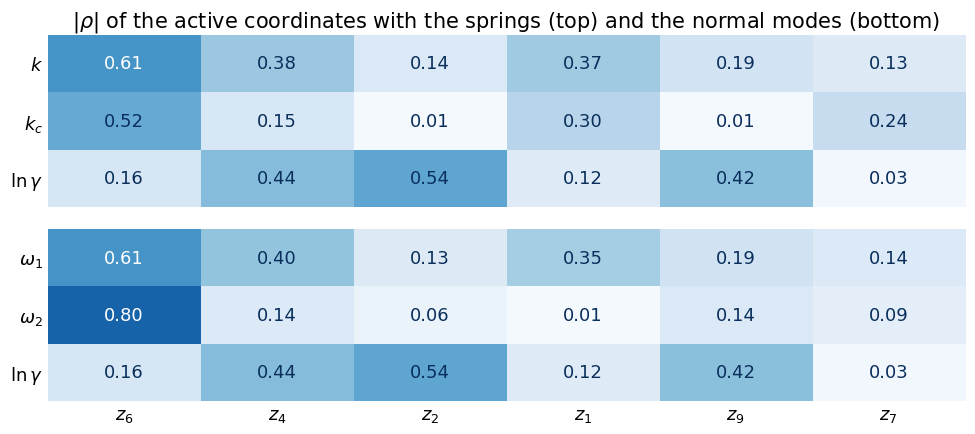

In [31]:
key2 = max(vaes2, key=lambda kk: summary2[kk]["c_mod"].max(0)[:2].sum() + summary2[kk]["c_spr"].max(0)[:2].sum())
s2 = summary2[key2]
print(f"model shown: beta = {key2[0]}, seed = {key2[1]}")
print("rows: active coordinates; columns: k, k_c, ln gamma | omega_1, omega_2, ln gamma | x1(0), x2(0), v1(0), v2(0)")
print(np.round(np.c_[s2["c_spr"], s2["c_mod"], s2["c_ic"]], 2))
fig, axs = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for a, Cm, labels in [(axs[0], s2["c_spr"].T, ["$k$", "$k_c$", r"$\ln\gamma$"]),
                      (axs[1], s2["c_mod"].T, [r"$\omega_1$", r"$\omega_2$", r"$\ln\gamma$"])]:
    a.imshow(Cm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(Cm):
        a.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=13, color="white" if v > 0.6 else navy)
    a.set_yticks(range(3)); a.set_yticklabels(labels)
    a.spines[:].set_visible(False); a.tick_params(length=0)
axs[0].set_title(r"$|\rho|$ of the active coordinates with the springs (top) and the normal modes (bottom)", fontsize=15)
axs[1].set_xticks(range(len(s2["active"]))); axs[1].set_xticklabels([f"$z_{{{k}}}$" for k in s2["active"]])
plt.tight_layout(); save_fig(fig, "traj_modes.png"); plt.show()
nums["two_show"] = {"beta": key2[0], "seed": key2[1], "c_spr": np.round(s2["c_spr"], 3).tolist(), "c_mod": np.round(s2["c_mod"], 3).tolist(),
                    "c_ic": np.round(s2["c_ic"], 3).tolist(), "active": [int(k) for k in s2["active"]]}

The figure shows seed 0. Its most informative coordinate $z_6$ follows $\omega_2$ with $|\rho|$ of 0.80 and $k_c$ with only 0.52. A coordinate that followed $k_c$ perfectly would have 0.75 with $\omega_2$, and one that followed $\omega_2$ perfectly would have 0.75 with $k_c$ and 0.63 with $k$. The measured values, 0.80 with $\omega_2$, 0.52 with $k_c$ and 0.61 with $k$, are those of a coordinate that tracks the anti-phase frequency, so the β-VAE describes the coupling through the normal-mode frequency $\omega_2$. The same coordinate correlates with $\omega_1$ at 0.61, and no other coordinate follows $\omega_1$ or $k$ above 0.40, so the in-phase frequency has no coordinate of its own. The friction is spread over three coordinates with $|\rho|$ of 0.42 to 0.54, each together with an initial position. The initial conditions take the remaining coordinates, $x_1(0)$ with 0.79, $x_2(0)$ with 0.52 to 0.56 in three coordinates, and the two initial velocities with 0.46 in one coordinate. With seven factors and only six active coordinates the problem is harder than for one oscillator, and, as there, only part of the factors is captured in single coordinates.

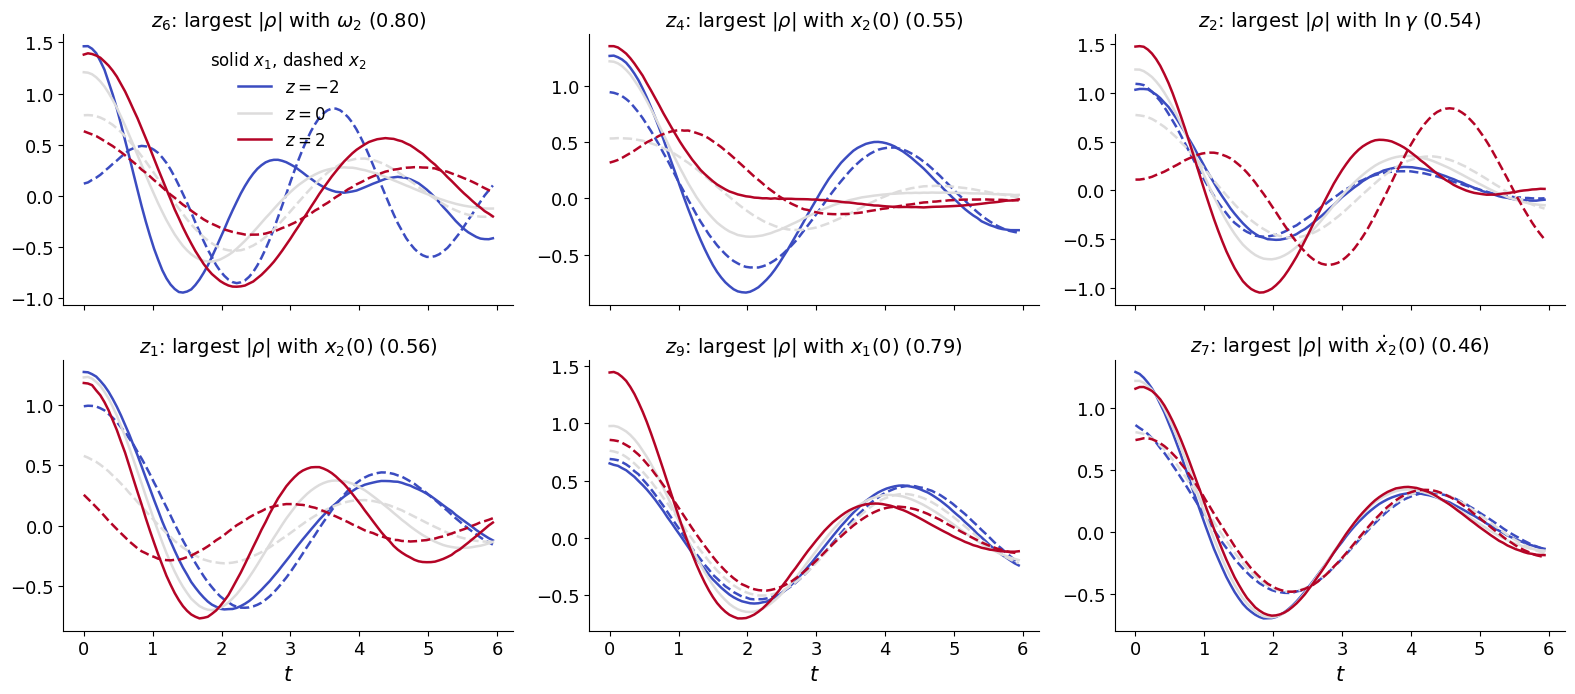

reference sample: k = 2.50, k_c = 0.96, gamma = 0.58, x1(0) = 1.16, x2(0) = 0.83


In [32]:
ref2 = int(np.argmin(np.abs(F2te[:, 0] - 2.5) + np.abs(F2te[:, 1] - 1.0) + np.abs(F2te[:, 2] - 0.5)))
mu_ref2 = ev2[key2][0][ref2]
coords2 = list(s2["active"][:6])
fig, axs = plt.subplots(int(np.ceil(len(coords2) / 3)), 3, figsize=(16, 3.6 * np.ceil(len(coords2) / 3)), squeeze=False, sharex=True)
for a, kz in zip(axs.ravel(), coords2):
    for v in [-2, 0, 2]:
        Z = mu_ref2.copy(); Z[kz] = v
        cv = decode(vaes2[key2], Z[None])[0].reshape(2, T_POINTS)
        col = plt.cm.coolwarm((v + 2) / 4)
        a.plot(t_grid, cv[0], color=col, lw=1.8, label=f"$z={v}$")
        a.plot(t_grid, cv[1], color=col, lw=1.8, ls="--")
    r = list(s2["active"]).index(kz)
    cand = [("k", s2["c_spr"][r, 0]), ("k_c", s2["c_spr"][r, 1]), (r"\omega_1", s2["c_mod"][r, 0]),
            (r"\omega_2", s2["c_mod"][r, 1]), (r"\ln\gamma", s2["c_mod"][r, 2]),
            ("x_1(0)", s2["c_ic"][r, 0]), ("x_2(0)", s2["c_ic"][r, 1]), (r"\dot x_1(0)", s2["c_ic"][r, 2]), (r"\dot x_2(0)", s2["c_ic"][r, 3])]
    nm, vv = max(cand, key=lambda p: p[1])
    a.set_title(rf"$z_{{{kz}}}$: largest $|\rho|$ with ${nm}$ ({vv:.2f})", fontsize=14)
for a in axs.ravel()[len(coords2):]: a.axis("off")
axs[0, 0].legend(fontsize=12, title="solid $x_1$, dashed $x_2$", title_fontsize=12)
for a in axs[-1]: a.set_xlabel("$t$")
plt.tight_layout(); plt.show()
print("reference sample: k = %.2f, k_c = %.2f, gamma = %.2f, x1(0) = %.2f, x2(0) = %.2f" % tuple(F2te[ref2, :5]))

The traversals show the coordinates at work on a sample with $k$ of 2.50, $k_c$ of 0.96 and $\gamma$ of 0.58. Moving $z_6$ changes the initial position of the second mass (dashed) and the relative motion of the two masses. At $z=-2$ the second mass oscillates quickly against the first, and at $z=2$ its motion is slower and smaller. This is a change of the anti-phase content and of its frequency. The other coordinates change mainly the initial positions and velocities and, together with them, the damping of the decoded motion.

## Summary

We integrated the Langevin equation (1) of a damped oscillator with white noise by the Euler–Maruyama scheme, whose noise term scales as the square root of the time step. Its mean and stationary variance agree with the exact results (11) and (19) up to an error of order $\Delta t$, about 5% for the variance at $\Delta t=0.01$.

A β-VAE with a Gaussian decoder, trained on 20 000 noisy trajectories without labels, uses four latent coordinates for the four factors for $\beta$ between 0.5 and 4 in every seed, and at $\beta=8$ it drops the initial velocity, the least visible factor. The damping is the one physical parameter that ends up in a coordinate of its own, with $|\rho|$ between 0.80 and 0.83 averaged over seeds. In the overdamped regime this coordinate follows $\omega^2/\gamma$, the slow decay rate, which is the combination the data contain. The frequency is stored together with the initial position, because the accuracy with which the encoder can measure a frequency is limited by how visible the oscillation is. The mutual information gap stays between 0.040 and 0.130 for all $\beta$ and seeds, against 0.916 for the true factors. The Fisher information of the trajectories explains this ranking. The visibility of a parameter decides whether it is stored, and the overlap of the sensitivity directions together with the nonlinearity of the map decides whether it is stored in a coordinate of its own.

The question-and-answer network SciNet of Iten et al. reproduces their result, one neuron for $\kappa$ and one for $b$ with $|\rho|$ of 0.99 and 0.98 and a prediction error of 1.8% after 1000 epochs, and the β-VAE finds the same two parameters with a stronger KL term after 60 epochs. Weak noise changes little, while nuisance initial conditions change which parameters are stored first. For two coupled masses the β-VAE stores the anti-phase normal-mode frequency $\omega_2$ in one coordinate ($|\rho|$ of 0.80, against 0.52 with the coupling spring) and has no coordinate of its own for the in-phase frequency.

A latent coordinate thus becomes interpretable when its parameter is visible in the data and no other parameter changes the data in a similar way, and a coordinate has to be checked against known physics before it is given a name.

## Exercises

### Exercise 1: Euler–Maruyama for a free Brownian particle

A free overdamped Brownian particle obeys
$$
\dot x=\sqrt{2D}\,\xi(t). \tag{57}
$$
(a) Write the Euler–Maruyama update and show that, for a start at the origin, the mean squared displacement after $n$ steps is given by equation (59) for every step size $\Delta t$. (b) Explain why the noise term must scale as $\sqrt{\Delta t}$, by computing the mean squared displacement at a fixed time for a noise term that scales as $\Delta t$. (c) Check (a) numerically for two step sizes.

#### Solution

(a) The update and its solution are
$$
x_{n+1}=x_n+\sqrt{2D\,\Delta t}\,\eta_n,\qquad x_n=\sqrt{2D\,\Delta t}\sum_{j<n}\eta_j, \tag{58}
$$
and since the $\eta_j$ are independent with unit variance,
$$
\langle x_n^2\rangle=2D\,\Delta t\,n=2Dt_n. \tag{59}
$$
The scheme is exact for this equation at any $\Delta t$. (b) With a noise term proportional to $\Delta t\,\eta_n$ we would get
$$
\langle x_n^2\rangle\propto n\,\Delta t^2=t_n\,\Delta t, \tag{60}
$$
which vanishes as the step size goes to zero, so the particle would stop diffusing in the continuum limit. Only the factor $\sqrt{\Delta t}$ gives a limit independent of the step size. (c) The simulation uses $D=0.5$ and the time 2, where equation (59) gives 2.

In [33]:
# free Brownian particle: x_{n+1} = x_n + sqrt(2 D dt) eta_n,  x_0 = 0  ->  <x_n^2> = 2 D n dt for every dt
D_ex, n_walk = 0.5, 200_000
for dt_ex in [0.5, 0.05]:
    steps = int(round(2.0 / dt_ex))
    x = np.zeros(n_walk)
    rng = np.random.default_rng(0)
    for _ in range(steps):
        x += np.sqrt(2 * D_ex * dt_ex) * rng.standard_normal(n_walk)
    print(f"dt = {dt_ex}: <x^2>(t = 2) = {np.mean(x**2):.4f},  exact 2 D t = {2 * D_ex * 2.0:.4f}")

dt = 0.5: <x^2>(t = 2) = 1.9908,  exact 2 D t = 2.0000


dt = 0.05: <x^2>(t = 2) = 1.9986,  exact 2 D t = 2.0000


Both step sizes reproduce the value 2 of equation (59) within the sampling error, about 0.3% for 200 000 walkers, with 1.9908 for $\Delta t=0.5$ and 1.9986 for $\Delta t=0.05$.

### Exercise 2: Stationary variance of the Ornstein–Uhlenbeck process

In the overdamped limit the oscillator obeys equation (20). (a) Check that
$$
x(t)=\int_0^te^{-r(t-s)}\,\frac{\sqrt{2D}}{\gamma}\,\xi(s)\,ds,\qquad r=\frac{\omega^2}{\gamma}, \tag{61}
$$
solves it for a start at the origin. (b) Using equation (3), compute the mean squared position at time $t$ and its limit for large $t$, and compare it with the underdamped result (19).

#### Solution

(a) Differentiating equation (61) gives
$$
\dot x=\frac{\sqrt{2D}}{\gamma}\,\xi(t)-r\,x(t), \tag{62}
$$
which is equation (20) divided by $\gamma$. (b) The delta correlation of the noise removes one integral,
$$
\langle x^2\rangle=\frac{2D}{\gamma^2}\int_0^t\!\!\int_0^te^{-r(t-s)}e^{-r(t-s')}\delta(s-s')\,ds\,ds'=\frac{2D}{\gamma^2}\int_0^te^{-2r(t-s)}ds, \tag{63}
$$
and we evaluate the remaining integral with SymPy.

In [34]:
s_, tau, D_, g_, w_s = sp.symbols("s tau D gamma omega", positive=True)
r_ = w_s**2 / g_                                                  # relaxation rate of the overdamped particle
# x(t) = int_0^t e^{-r (t - s)} (sqrt(2D)/gamma) xi(s) ds  ->  <x^2> = (2D/gamma^2) int_0^t e^{-2 r (t - s)} ds
var_t = (2 * D_ / g_**2) * sp.integrate(sp.exp(-2 * r_ * (tau - s_)), (s_, 0, tau))
print("<x^2>(t) =", sp.simplify(var_t))
print("t -> infinity:", sp.limit(var_t, tau, sp.oo))

<x^2>(t) = D/(gamma*omega**2) - D*exp(-2*omega**2*tau/gamma)/(gamma*omega**2)


t -> infinity: D/(gamma*omega**2)


The limit is
$$
\lim_{t\to\infty}\langle x^2\rangle=\frac{D}{\gamma\omega^2}, \tag{64}
$$
the same as the position variance of the full oscillator in equation (19). The stationary distribution of the position is independent of the mass, as it must be for a Boltzmann distribution in the potential of the spring,
$$
p(x)\propto e^{-\omega^2x^2/(2k_BT)},\qquad k_BT=D/\gamma, \tag{65}
$$
in units with unit mass and in agreement with the Einstein relation (4).

### Exercise 3: A stronger random force

Generate the trajectory data with a noise strength $D$ ten times larger and train a β-VAE with $\beta=4$ (60 epochs suffice for a first look). Describe how the rate, the distortion, the number of active coordinates and the best correlations with the four factors change, and relate the answer to the noise floor (31).

#### Solution

In [35]:
# a ten times larger noise strength
Xtr_D, _ = make_oscillator_data(20_000, seed=31, D=10 * D_NOISE)
Xte_D, Fte_D = make_oscillator_data(5_000, seed=32, D=10 * D_NOISE)
vae_D, _ = train(lambda: TrajVAE(T_POINTS, D_LATENT), partial(beta_vae_loss, beta=4), (torch.as_tensor(Xtr_D),), 60, 0,
                 name="traj_ex_D10_beta4", log_every=30)
mu_D, lv_D, R_D, Drec_D = evaluate(vae_D, Xte_D)
act_D = np.flatnonzero(kl_per_dim(mu_D, lv_D).mean(0) > ACTIVE_NATS)
dev_D = Xte_D - mean_trajectories(Fte_D, t_grid)
print(f"D = {10 * D_NOISE}: rms deviation from the mean trajectory {np.sqrt((dev_D**2).mean()):.4f}, "
      f"noise floor {((dev_D**2).sum(-1) / (2 * SIGMA_X**2)).mean():.2f} nats")
print(f"D = {10 * D_NOISE}: rate {R_D:.2f} nats, distortion {Drec_D:.2f}, active coordinates {len(act_D)}")
print("best |rho| over active coordinates (omega, ln gamma, x0, v0):", np.round(abs_corr(mu_D, probe_factors(Fte_D))[act_D].max(0), 2))
print("for comparison, D = %.3f, beta = 4 (mean over seeds):" % D_NOISE, np.round(np.mean([best_corr[4, s] for s in SEEDS], 0), 2),
      " rate", np.round(np.mean([ev[4, s][2] for s in SEEDS]), 2), " distortion", np.round(np.mean([ev[4, s][3] for s in SEEDS]), 2))

  traj_ex_D10_beta4 epoch   30: loss 41.537  rec 14.376  kl 6.790   ( 58.8 s)


  traj_ex_D10_beta4 epoch   60: loss 40.631  rec 13.903  kl 6.682   ( 82.1 s)
D = 0.02: rms deviation from the mean trajectory 0.0946, noise floor 44.70 nats
D = 0.02: rate 6.75 nats, distortion 13.53, active coordinates 5
best |rho| over active coordinates (omega, ln gamma, x0, v0): [0.48 0.8  0.62 0.45]
for comparison, D = 0.002, beta = 4 (mean over seeds): [0.51 0.82 0.58 0.56]  rate 5.84  distortion 9.34


With $D=0.02$ the root-mean-square deviation of a trajectory from its mean grows from 0.0315 to 0.0946, three times more, and the noise floor (31) grows from 4.96 to 44.70 nats. The model has five active coordinates instead of four, a rate of 6.75 nats instead of 5.84 (mean over the seeds at $D=0.002$) and a distortion of 13.53 nats instead of 9.34. The distortion lies far below the new noise floor, so the fifth coordinate and the larger rate are spent on the slow, correlated displacement caused by the noise. The best correlations with $\omega$, $\ln\gamma$ and $v_0$ drop from 0.51, 0.82 and 0.56 to 0.48, 0.80 and 0.45, while the one with $x_0$ rises from 0.58 to 0.62. The damping and the initial position, the most visible factors, are affected least. These conclusions rest on a single seed with 60 epochs, and several seeds are needed to make them firm.

### Exercise 4: A driving frequency as a third parameter

Add a periodic force to the equation of motion,
$$
\ddot x=-\omega^2x-\gamma\dot x+F\cos(\Omega t)+\sqrt{2D}\,\xi(t), \tag{66}
$$
with $F=0.5$, and draw $\Omega$ uniformly between 0.5 and 2.5 for every trajectory. Train a β-VAE with $\beta=4$ and correlate its active coordinates with $(\omega,\ln\gamma,\Omega,x_0,v_0)$. Determine whether a coordinate follows the driving frequency, which of the five factors is easiest to find, and explain the ranking.

#### Solution

In [36]:
# a third physical parameter: the frequency Omega of a driving force F cos(Omega t), F = 0.5
F_DRIVE = 0.5
def make_driven(n, seed):
    rng = np.random.default_rng(seed)
    om, ga = rng.uniform(*OMEGA_RANGE, n), np.exp(rng.uniform(*np.log(GAMMA_RANGE), n))
    Om, x0, v0 = rng.uniform(0.5, 2.5, n), rng.uniform(*X0_RANGE, n), rng.uniform(-V0_MAX, V0_MAX, n)
    X, _ = simulate(om, ga, x0, v0, rng, drive=lambda tt: F_DRIVE * np.cos(Om * tt))
    return X.astype(np.float32), np.stack([om, np.log(ga), Om, x0, v0], 1)

Xtr_dr, _ = make_driven(20_000, 41)
Xte_dr, Pte_dr = make_driven(5_000, 42)
vae_dr, _ = train(lambda: TrajVAE(T_POINTS, D_LATENT), partial(beta_vae_loss, beta=4), (torch.as_tensor(Xtr_dr),), 60, 0,
                  name="traj_ex_driven_beta4", log_every=30)
mu_dr, lv_dr, _, _ = evaluate(vae_dr, Xte_dr)
kl_dr = kl_per_dim(mu_dr, lv_dr).mean(0); act_dr = np.flatnonzero(kl_dr > ACTIVE_NATS)
act_dr = act_dr[np.argsort(kl_dr[act_dr])[::-1]]
print("active coordinates:", len(act_dr), " mean KL (nats):", np.round(kl_dr[act_dr], 2))
print("|rho| (rows: active coordinates by decreasing KL; columns: omega, ln gamma, Omega, x0, v0)")
print(np.round(abs_corr(mu_dr, Pte_dr)[act_dr], 2))

  traj_ex_driven_beta4 epoch   30: loss 45.887  rec 13.662  kl 8.056   ( 25.8 s)


  traj_ex_driven_beta4 epoch   60: loss 44.345  rec 12.859  kl 7.871   ( 58.2 s)
active coordinates: 5  mean KL (nats): [2.69 2.19 1.34 1.33 0.46]
|rho| (rows: active coordinates by decreasing KL; columns: omega, ln gamma, Omega, x0, v0)
[[0.41 0.73 0.26 0.02 0.08]
 [0.43 0.29 0.05 0.28 0.19]
 [0.01 0.34 0.49 0.03 0.23]
 [0.17 0.02 0.07 0.72 0.14]
 [0.38 0.28 0.   0.24 0.11]]


The driven model has five active coordinates. The driving frequency is found only partially. Its best coordinate reaches $|\rho|$ of 0.49 with $\Omega$ and 0.34 with $\ln\gamma$. The damping (0.73) and the initial position (0.72) are the factors found best, each with its own coordinate, while $\omega$ reaches only 0.43 and shares coordinates with $\ln\gamma$, and $v_0$ reaches 0.23. The driving force adds a response whose amplitude depends on $\omega$, $\gamma$ and $\Omega$ together,
$$
A(\Omega)=\frac{F}{\sqrt{(\omega^2-\Omega^2)^2+\gamma^2\Omega^2}}, \tag{67}
$$
and within six time units the driven oscillation is still mixed with the transient. The driving frequency is therefore only moderately visible and is confused with the other two rates.

### Exercise 5: Hopping in a double well

This exercise is open. Replace the spring by a double-well potential, with the equation of motion
$$
V(x)=a\,(x^2-1)^2,\qquad\ddot x=-V'(x)-\gamma\dot x+\sqrt{2D}\,\xi(t), \tag{68}
$$
and vary the barrier height $a$ and the temperature, given by the Einstein relation (4) with unit mass, between trajectories. Choose a time window long enough to see several jumps between the wells. The mean time between jumps follows Kramers' law [Kramers 1940, Hänggi, Talkner and Borkovec 1990],
$$
\tau\propto e^{a/k_BT}. \tag{69}
$$
Train a β-VAE on the trajectories and test whether a latent coordinate follows $\ln\tau$, which is the ratio of $a$ and $k_BT$, or $a$ and $T$ separately. The time of the first jump is random and differs between trajectories with the same parameters, so the encoder must summarise statistics of the trajectory. A summary input such as the histogram of $x$ or the sequence of well occupations may work better than the raw positions.

### Exercise 6: Long training with noise and nuisance factors

This exercise is open. We trained SciNet for 1000 epochs only in the noise-free setting of the paper. Train it for 1000 epochs also on the data with noise and on the data with noise and random initial conditions (five latent neurons). Check whether it then stores $\kappa$, $b$, $x_0$ and $v_0$ in separate neurons, compare with the β-VAE, and explain the result through the cost (43) by asking which parameters improve the answers to the questions between 0 and 10 the most.

In [37]:
nums["runtime_s"] = round(time.time() - t_start, 1)
with open(f"{RES}/traj_numbers.json", "w") as fh:
    json.dump(nums, fh, indent=1)
print(f"numbers saved to {RES}/traj_numbers.json; total run time {nums['runtime_s']} s")

numbers saved to results/traj_numbers.json; total run time 13086.2 s


## References

- R. Iten, T. Metger, H. Wilming, L. del Rio, R. Renner, Discovering physical concepts with neural networks, Phys. Rev. Lett. 124, 010508 (2020), [doi:10.1103/PhysRevLett.124.010508](https://doi.org/10.1103/PhysRevLett.124.010508), open-access version with the Supplemental Material at [arXiv:1807.10300](https://arxiv.org/abs/1807.10300).
- I. Higgins, L. Matthey, A. Pal, C. Burgess, X. Glorot, M. Botvinick, S. Mohamed, A. Lerchner, β-VAE: Learning basic visual concepts with a constrained variational framework, ICLR 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl).
- F. Locatello, S. Bauer, M. Lucic, G. Rätsch, S. Gelly, B. Schölkopf, O. Bachem, Challenging common assumptions in the unsupervised learning of disentangled representations, ICML 2019, PMLR 97, 4114–4124, [arXiv:1811.12359](https://arxiv.org/abs/1811.12359).
- R. T. Q. Chen, X. Li, R. Grosse, D. Duvenaud, Isolating sources of disentanglement in variational autoencoders, NeurIPS 2018, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942) (mutual information gap).
- P. E. Kloeden, E. Platen, Numerical Solution of Stochastic Differential Equations, Springer (1992), [doi:10.1007/978-3-662-12616-5](https://doi.org/10.1007/978-3-662-12616-5).
- D. J. Higham, An algorithmic introduction to numerical simulation of stochastic differential equations, SIAM Rev. 43, 525 (2001), [doi:10.1137/S0036144500378302](https://doi.org/10.1137/S0036144500378302).
- G. E. Uhlenbeck, L. S. Ornstein, On the theory of the Brownian motion, Phys. Rev. 36, 823 (1930), [doi:10.1103/PhysRev.36.823](https://doi.org/10.1103/PhysRev.36.823).
- S. Chandrasekhar, Stochastic problems in physics and astronomy, Rev. Mod. Phys. 15, 1 (1943), [doi:10.1103/RevModPhys.15.1](https://doi.org/10.1103/RevModPhys.15.1).
- H. A. Kramers, Brownian motion in a field of force and the diffusion model of chemical reactions, Physica 7, 284 (1940), [doi:10.1016/S0031-8914(40)90098-2](https://doi.org/10.1016/S0031-8914(40)90098-2).
- P. Hänggi, P. Talkner, M. Borkovec, Reaction-rate theory: fifty years after Kramers, Rev. Mod. Phys. 62, 251 (1990), [doi:10.1103/RevModPhys.62.251](https://doi.org/10.1103/RevModPhys.62.251).